# Лабораторная работа 1. Кто снизил активность и почему



## 0. Окружение и настройки

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

RAW_CLIENTS = "clients.csv"
RAW_TXN = "transactions.csv"

## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

In [ ]:

clients = pd.read_csv(
    RAW_CLIENTS,
    sep=",",
    encoding="utf-8",
    dtype={"client_id": "string", "branch_code": "string"}
)

transactions = pd.read_csv(
    RAW_TXN,
    sep=";",
    encoding="cp1251",
    decimal=",",
    dtype={
        "txn_id": "string",
        "client_id": "string",
        "mcc_code": "string"
    }
)

print("Клиенты:", clients.shape)
print("Транзакции:", transactions.shape)

display(clients.head())
display(transactions.head())


Клиенты: (5704, 16)
Транзакции: (625949, 9)


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C001917,1972-11-12,Ж,Новосибирск,Массовый,Базовый,Дебетовая,07.12.2019,30.09.2021,Зарплата в другом банке,44200.0,Нет,NaN,NaN,00182,Да
1,C004159,1986-04-22,Ж,Санкт-Петербург,Зарплатный,Серебро,Кредитная,04.01.2014,04.08.2017,Зарплата в нашем банке,103000.0,Да,2024-05,1.0,00458,Да
2,C003190,1978-08-03,Ж,ЕКАТЕРИНБУРГ,Зарплатный,Базовый,Дебетовая,10.01.2022,06.11.2022,Зарплата в нашем банке,100300.0,Да,2024-09,NaN,00874,Да
3,C005429,1960-03-19,Ж,Москва,Массовый,Золото,Дебетовая,01.04.2018,20.01.2022,Зарплата в другом банке,41300.0,Да,2024-01,5.0,00903,Да
4,C002266,1944-10-29,М,Нижний Новгород,Массовый,Базовый,Дебетовая,19.08.2016,24.03.2022,Зарплата в нашем банке,59600.0,Нет,NaN,NaN,00860,Да


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990072,C002648,2023-11-23 13:46:01,453.71,RUB,Связь и интернет,4814,Токен,успешно
1,990124,C003671,2023-11-27 04:39:24,914.26,RUB,Связь и интернет,4814,СБП,успешно
2,990077,C000967,2023-11-30 19:50:36,1051.04,RUB,Продукты,5411,Карта,успешно
3,990180,C001934,2023-12-10 16:24:50,767.41,RUB,Продукты,5411,Токен,успешно
4,990062,C000522,2023-12-12 13:14:20,976.97,RUB,Развлечения и досуг,7832,Онлайн-банк,успешно


## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

In [ ]:

print("Размер таблицы клиентов:", clients.shape)
print("Размер таблицы транзакций:", transactions.shape)

print("\nТипы данных клиентов:")
print(clients.dtypes)

print("\nТипы данных транзакций:")
print(transactions.dtypes)


Размер таблицы клиентов: (5704, 16)
Размер таблицы транзакций: (625949, 9)

Типы данных клиентов:
client_id             string[python]
birth_date                    object
gender                        object
city                          object
segment                       object
loyalty_tier                  object
card_type                     object
registration_date             object
card_open_date                object
income_source                 object
monthly_income               float64
has_mobile_app                object
app_last_login                object
satisfaction_score           float64
branch_code           string[python]
marketing_opt_in              object
dtype: object

Типы данных транзакций:
txn_id          string[python]
client_id       string[python]
txn_datetime            object
amount                 float64
currency                object
category                object
mcc_code        string[python]
channel                 object
status                 

In [ ]:

print("Таблица clients:")
print("Всего строк:", len(clients))
print("Уникальных ID:", clients["client_id"].nunique())
print("Пропусков ID:", clients["client_id"].isna().sum())
print("Повторных ID:", clients.duplicated("client_id").sum())

print("\nТранзакции transactions:")
print("Всего строк:", len(transactions))
print("Уникальных ID:", transactions["txn_id"].nunique())
print("Пропусков ID:", transactions["txn_id"].isna().sum())
print("Повторных ID:", transactions.duplicated("txn_id").sum())


Таблица clients:
Всего строк: 5704
Уникальных ID: 5649
Пропусков ID: 0
Повторных ID: 55

Транзакции transactions:
Всего строк: 625949
Уникальных ID: 624449
Пропусков ID: 0


Повторных ID: 1500


### 2.2. Дубли

In [ ]:

for name, df, key in [
    ("Клиенты", clients, "client_id"),
    ("Транзакции", transactions, "txn_id")
]:
    print(f"\n{name}")
    print("Полные дубликаты:", df.duplicated().sum())
    print("Повторные ключи:", df.duplicated(subset=key).sum())
    print("Уникальных ключей:", df[key].nunique())



Клиенты
Полные дубликаты: 40
Повторные ключи: 55
Уникальных ключей: 5649

Транзакции


Полные дубликаты: 1279
Повторные ключи: 1500
Уникальных ключей: 624449


### 2.3. Соответствие данных описанию полей из задания

In [ ]:

print("Категориальные признаки в таблице клиентов")

for col in ["gender", "city", "segment", "loyalty_tier",
            "card_type", "income_source", "has_mobile_app",
            "marketing_opt_in"]:
    print(f"\n{col}: {clients[col].nunique()} значений")
    print(clients[col].unique())


Категориальные признаки в таблице клиентов

gender: 2 значений
['Ж' 'М']

city: 17 значений
['Новосибирск' 'Санкт-Петербург' 'ЕКАТЕРИНБУРГ' 'Москва' 'Нижний Новгород'
 'Екатеринбург' 'Казань' 'г. Санкт-Петербург' 'МОСКВА' ' москва'
 'Н. Новгород' 'г. Новосибирск' 'СПб' 'г. Москва' 'г.Екатеринбург'
 'казань' 'Санкт Петербург']

segment: 4 значений
['Массовый' 'Зарплатный' 'Премиальный' 'Private']

loyalty_tier: 4 значений
['Базовый' 'Серебро' 'Золото' 'Платина']

card_type: 3 значений
['Дебетовая' 'Кредитная' 'Премиальная']

income_source: 3 значений
['Зарплата в другом банке' 'Зарплата в нашем банке' 'Не указан']

has_mobile_app: 2 значений
['Нет' 'Да']

marketing_opt_in: 2 значений
['Да' 'Нет']


In [ ]:

print("Категориальные признаки в таблице транзакций")

for col in ["currency", "category", "channel", "status"]:
    print(f"\n{col}: {transactions[col].nunique()} значений")
    print(transactions[col].unique())


Категориальные признаки в таблице транзакций



currency: 3 значений
['RUB' 'EUR' 'USD']

category: 12 значений
['Связь и интернет' 'Продукты' 'Развлечения и досуг' 'Онлайн-сервисы'
 'Аптеки' 'АЗС' 'Транспорт' 'Одежда и обувь' 'кафе и рестораны'
 'Кафе и рестораны' 'Связь и Интернет' 'Кафе/рестораны']

channel: 4 значений


['Токен' 'СБП' 'Карта' 'Онлайн-банк']



status: 3 значений


['успешно' 'возврат' 'отклонено']


In [ ]:

print("Минимальная оценка:", clients["satisfaction_score"].min())
print("Максимальная оценка:", clients["satisfaction_score"].max())

print("Количество записей с отрицательным доходом:",
      (clients["monthly_income"] < 0).sum())


Минимальная оценка: 1.0
Максимальная оценка: 5.0
Количество записей с отрицательным доходом: 57


In [ ]:
dates = transactions["txn_datetime"].str[:10]

print("Первая дата:", dates.min())
print("Последняя дата:", dates.max())

Первая дата: 2023-11-23


Последняя дата: 2026-08-02


In [ ]:

pd.crosstab(transactions["category"], transactions["mcc_code"])


mcc_code,4111,4814,5411,5541,5651,5812,5815,5912,7832
category,,,,,,,,,
АЗС,20,16,16,58107,17,19,17,15,16
Аптеки,17,12,13,21,18,19,14,44915,12
Кафе и рестораны,17,13,18,20,15,48507,16,13,28
Кафе/рестораны,7,9,6,4,5,16478,3,6,9
Одежда и обувь,24,27,24,20,64720,27,22,15,24
Онлайн-сервисы,17,11,17,10,13,14,43211,19,16
Продукты,52,54,164370,66,42,52,48,50,49
Развлечения и досуг,14,18,14,23,16,13,19,15,47782
Связь и Интернет,5,19401,8,5,4,3,7,9,6


### 2.4. Связь между таблицами

In [ ]:
unknown_clients = transactions[~transactions["client_id"].isin(clients["client_id"])]

print("Число таких транзакций, в которых ключ клиента не определён в таблице clients:", len(unknown_clients))
print("Уникальных клиентов:", unknown_clients["client_id"].nunique())

Число таких транзакций, в которых ключ клиента не определён в таблице clients: 28598
Уникальных клиентов: 351


In [ ]:

clients_without_txn = clients[
    ~clients["client_id"].isin(transactions["client_id"])
]

print("Клиентов без транзакций:",
      clients_without_txn["client_id"].nunique())


Клиентов без транзакций: 8


In [ ]:

merged = transactions.merge(
    clients,
    on="client_id",
    how="left"
)

print("До объединения:", len(transactions))
print("После объединения:", len(merged))
print("Изменение числа записей:", len(merged) - len(transactions))

До объединения: 625949
После объединения: 631949
Изменение числа записей: 6000


**Вывод по аудиту.** Выгрузка клиентов содержит 5704 строки и 5649 уникальных `client_id`; найдено 40 полных дубликатов и ещё 15 повторных ключей с расхождениями. В выгрузке операций — 625949 строк, 1279 полных дубликатов и 221 дополнительный повтор `txn_id` после удаления полных дублей.

Выявлены разные написания городов и категорий покупок, 57 значений дохода `-999`, 74 операции вне исследуемого периода и расхождения между MCC-кодом и категорией. У 351 идентификатора клиента (28598 исходных операций) нет соответствующей записи в справочнике; 8 клиентов из справочника не имеют транзакций.

Если объединять исходные таблицы до разрешения повторяющихся `client_id`, количество строк увеличивается, а операции некоторых клиентов дублируются. Поэтому сначала устраняем проблемы ключей, затем выполняем аналитическое объединение.

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

### 3.1. Типы, даты, числа

In [ ]:
clients_clean = clients.copy()
transactions_clean = transactions.copy()

In [ ]:

# Даты в таблице клиентов
clients_clean["birth_date"] = pd.to_datetime(
    clients_clean["birth_date"], format="%Y-%m-%d", errors="coerce"
)

clients_clean["registration_date"] = pd.to_datetime(
    clients_clean["registration_date"], format="%d.%m.%Y", errors="coerce"
)

clients_clean["card_open_date"] = pd.to_datetime(
    clients_clean["card_open_date"], format="%d.%m.%Y", errors="coerce"
)

clients_clean["app_last_login"] = pd.to_datetime(
    clients_clean["app_last_login"], format="%Y-%m", errors="coerce"
)

# Даты в таблице транзакций
transactions_clean["txn_datetime"] = pd.to_datetime(
    transactions_clean["txn_datetime"], format="mixed", errors="coerce"
)


In [ ]:

print("Типы дат для клиентов:")
print(clients_clean[[
    "birth_date",
    "registration_date",
    "card_open_date",
    "app_last_login"
]].dtypes)

print("\nТип даты для транзакций:")
print(transactions_clean["txn_datetime"].dtype)


Типы дат для клиентов:
birth_date           datetime64[ns]
registration_date    datetime64[ns]
card_open_date       datetime64[ns]
app_last_login       datetime64[ns]
dtype: object

Тип даты для транзакций:
datetime64[ns]


In [ ]:

# Изучаем отрицательные доходы
negative_income = clients_clean[
    clients_clean["monthly_income"] < 0
]

print("Количество отрицательных доходов:", len(negative_income))

print("\nУникальные значения:")
print(negative_income["monthly_income"].value_counts())

print("\nИсходные пропуски:")
print(clients_clean["monthly_income"].isna().sum())


Количество отрицательных доходов: 57

Уникальные значения:
monthly_income
-999.0    57
Name: count, dtype: int64

Исходные пропуски:
546


In [ ]:

# Количество значений -999 до замены
n_negative = (clients_clean["monthly_income"] == -999).sum()

# Замена на пропуски
clients_clean["monthly_income"] = clients_clean["monthly_income"].replace(
    -999, float("nan")
)


print("Всего пропусков:", clients_clean["monthly_income"].isna().sum())


Всего пропусков: 603


In [ ]:
# Удаляем полные дубликаты
clients_clean = clients_clean.drop_duplicates()
transactions_clean = transactions_clean.drop_duplicates()

print("Осталось записей в таблице клиентов:", len(clients_clean))
print("Осталось записей в таблице транзакций:", len(transactions_clean))

Осталось записей в таблице клиентов: 5664
Осталось записей в таблице транзакций: 624670


In [ ]:

print("Повторные client_id:",
      clients_clean.duplicated("client_id").sum())

print("Повторные txn_id:",
      transactions_clean.duplicated("txn_id").sum())


Повторные client_id: 15
Повторные txn_id: 221


In [ ]:

# Оставляем только различные строки без полных дубликатов
txn_unique = transactions.drop_duplicates()

# Находим повторяющиеся идентификаторы
duplicates = txn_unique[txn_unique.duplicated("txn_id", keep=False)]


display(duplicates.sort_values("txn_id").head(10))


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
2202,102190,C004561,2024-01-03 21:31:20,6336.09,RUB,Продукты,5411,Карта,успешно
2203,102190,C004561,2024-01-03,6336.09,RUB,Продукты,5411,Карта,успешно
4903,104885,C001292,2024-01-06 12:53:20,63.09,RUB,Транспорт,4111,СБП,успешно
4904,104885,C001292,2024-01-06,63.09,RUB,Транспорт,4111,СБП,успешно
10648,110616,C004262,2024-01-13,2354.74,RUB,Одежда и обувь,5651,Карта,успешно
10649,110616,C004262,2024-01-13 11:31:30,2354.74,RUB,Одежда и обувь,5651,Карта,успешно
11124,111090,C003142,2024-01-13 18:32:07,316.03,RUB,АЗС,5541,Карта,успешно
11125,111090,C003142,2024-01-13,316.03,RUB,АЗС,5541,Карта,успешно
18557,118509,C003080,2024-01-21 15:16:30,481.62,RUB,Связь и интернет,4814,Токен,успешно
18558,118509,C003080,2024-01-21,481.62,RUB,Связь и интернет,4814,Токен,успешно


In [ ]:

# Отмечаем записи с полным временем
transactions_clean["has_time"] = (
    transactions.loc[transactions_clean.index, "txn_datetime"]
    .str.len() > 10
)

# Сначала ставим записи вместе со временем
transactions_clean = transactions_clean.sort_values(
    "has_time", ascending=False
)

# Оставляем одну запись на операцию
transactions_clean = transactions_clean.drop_duplicates(
    subset="txn_id"
)

# Убираем вспомогательный столбец
transactions_clean = transactions_clean.drop(columns="has_time")

print("Осталось транзакций:", len(transactions_clean))
print("Повторных txn_id:",
      transactions_clean.duplicated("txn_id").sum())


Осталось транзакций: 624449
Повторных txn_id: 0


In [ ]:

# Дата окончания исследования
date = pd.Timestamp("2025-06-30")

# Возраст клиента
clients_clean["age"] = (
    date.year - clients_clean["birth_date"].dt.year
)

# Учитываем, был ли день рождения в 2025 году
birthday = (
    (clients_clean["birth_date"].dt.month > date.month) |
    (
        (clients_clean["birth_date"].dt.month == date.month) &
        (clients_clean["birth_date"].dt.day > date.day)
    )
)

clients_clean["age"] -= birthday

print("Минимальный возраст:", clients_clean["age"].min())
print("Максимальный возраст:", clients_clean["age"].max())

print("Клиентов младше 14 лет:",
      (clients_clean["age"] < 14).sum())

print("Клиентов старше 100 лет:",
      (clients_clean["age"] > 100).sum())


Минимальный возраст: 22
Максимальный возраст: 88
Клиентов младше 14 лет: 0
Клиентов старше 100 лет: 0


In [ ]:

# Находим некорректные даты
invalid_dates = clients_clean[clients_clean["registration_date"] > clients_clean["card_open_date"]]

print("Количество проблемных записей:", len(invalid_dates))




Количество проблемных записей: 0


### Вывод по разделу 3.1

Даты приведены к типу `datetime` для расчётов по календарным периодам; при преобразовании новых пропусков не возникло. Значения дохода `-999` трактованы как служебное обозначение отсутствующих сведений и заменены на `NaN` (603 пропуска на этапе до удаления дубликатов).

Удалены полные дубликаты записей. Для 221 дополнительно повторявшегося `txn_id` сохранена одна операция, причём предпочтение отдано записи с более точной датой и временем. После очистки — 624449 уникальных транзакций. Противоречивые клиентские ключи обрабатываются в следующем подразделе.

Возраст рассчитан по состоянию на 30.06.2025; проверены крайние значения и порядок дат регистрации и открытия карты. По этим проверкам нарушений не обнаружено.

### 3.2. Категориальные признаки

In [ ]:

city_mapping = {
    " москва": "Москва",
    "МОСКВА": "Москва",
    "г. Москва": "Москва",
    "СПб": "Санкт-Петербург",
    "г. Санкт-Петербург": "Санкт-Петербург",
    "Санкт Петербург": "Санкт-Петербург",
    "г. Новосибирск": "Новосибирск",
    "г.Екатеринбург": "Екатеринбург",
    "ЕКАТЕРИНБУРГ": "Екатеринбург",
    "Н. Новгород": "Нижний Новгород",
    "казань": "Казань"
}

# Считаем количество изменяемых записей
n_changed = clients_clean["city"].isin(city_mapping).sum()

# Нормализуем названия
clients_clean["city"] = clients_clean["city"].replace(city_mapping)

print("Изменено записей:", n_changed)
print("Уникальных городов:", clients_clean["city"].nunique())

print("\nРаспределение по городам:")
print(clients_clean["city"].value_counts())


Изменено записей: 1632
Уникальных городов: 6

Распределение по городам:
city
Москва             1642
Санкт-Петербург     987
Новосибирск         916
Екатеринбург        724
Нижний Новгород     706
Казань              689
Name: count, dtype: int64


In [ ]:
client_duplicates = clients_clean[
    clients_clean.duplicated("client_id", keep=False)
]
# Сортируем по идентификатору
client_duplicates = client_duplicates.sort_values("client_id")

print("Уникальных клиентов:", client_duplicates["client_id"].nunique())
print("Всего записей:", len(client_duplicates))

display(client_duplicates)

Уникальных клиентов: 15
Всего записей: 30


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in,age
2410,C000050,1980-03-25,М,Новосибирск,Массовый,Базовый,Кредитная,2014-12-19,2020-06-19,Не указан,60300.0,Нет,NaT,NaN,00492,Да,45
744,C000050,1980-03-25,М,Санкт-Петербург,Зарплатный,Базовый,Кредитная,2014-12-19,2020-06-19,Не указан,60300.0,Нет,NaT,NaN,00492,Да,45
990,C000145,1965-05-28,Ж,Новосибирск,Премиальный,Базовый,Дебетовая,2020-01-06,2021-12-13,Не указан,88200.0,Нет,NaT,2.0,00296,Да,60
2322,C000145,1965-05-28,Ж,Москва,Массовый,Базовый,Дебетовая,2020-01-06,2021-12-13,Не указан,88200.0,Нет,NaT,2.0,00296,Да,60
3462,C000201,1955-07-29,М,Новосибирск,Массовый,Серебро,Дебетовая,2014-04-19,2016-09-03,Зарплата в другом банке,130300.0,Да,2025-03-01,NaN,00322,Да,69
1828,C000201,1955-07-29,М,Нижний Новгород,Зарплатный,Серебро,Дебетовая,2014-04-19,2016-09-03,Зарплата в другом банке,130300.0,Да,2025-03-01,NaN,00322,Да,69
3265,C002334,1971-09-17,М,Екатеринбург,Private,Золото,Премиальная,2018-05-20,2022-05-04,Зарплата в другом банке,255300.0,Да,2024-09-01,2.0,00659,Да,53
2336,C002334,1971-09-17,М,Нижний Новгород,Private,Золото,Премиальная,2018-05-20,2022-05-04,Зарплата в другом банке,255300.0,Да,2024-09-01,2.0,00659,Да,53
299,C002393,1974-09-05,М,Новосибирск,Массовый,Базовый,Дебетовая,2021-10-05,2024-10-04,Зарплата в другом банке,82400.0,Да,2024-06-01,NaN,00626,Да,50
1098,C002393,1974-09-05,М,Нижний Новгород,Private,Базовый,Дебетовая,2021-10-05,2024-10-04,Зарплата в другом банке,82400.0,Да,2024-06-01,NaN,00626,Да,50


In [ ]:
display(client_duplicates[["client_id", "city", "segment"]])

,client_id,city,segment
2410,C000050,Новосибирск,Массовый
744,C000050,Санкт-Петербург,Зарплатный
990,C000145,Новосибирск,Премиальный
2322,C000145,Москва,Массовый
3462,C000201,Новосибирск,Массовый
1828,C000201,Нижний Новгород,Зарплатный
3265,C002334,Екатеринбург,Private
2336,C002334,Нижний Новгород,Private
299,C002393,Новосибирск,Массовый
1098,C002393,Нижний Новгород,Private


In [ ]:

# Находим клиентов с разными городами
city_conflicts = client_duplicates.groupby("client_id")["city"].nunique()
city_ids = city_conflicts[city_conflicts > 1].index

# Заменяем противоречивые города
clients_clean.loc[
    clients_clean["client_id"].isin(city_ids), "city"
] = pd.NA

# Аналогично для сегмента
segment_conflicts = client_duplicates.groupby("client_id")["segment"].nunique()
segment_ids = segment_conflicts[segment_conflicts > 1].index

clients_clean.loc[
    clients_clean["client_id"].isin(segment_ids), "segment"
] = pd.NA


In [ ]:

# Оставляем одну запись на клиента
clients_clean = clients_clean.drop_duplicates(
    subset="client_id"
).copy()

# Проверяем результат
print("Всего клиентов:", len(clients_clean))
print("Повторных ID:", clients_clean.duplicated("client_id").sum())

print("Пропусков city:", clients_clean["city"].isna().sum())
print("Пропусков segment:", clients_clean["segment"].isna().sum())


Всего клиентов: 5649
Повторных ID: 0
Пропусков city: 13
Пропусков segment: 10


In [ ]:

print("Количество категорий:",
      transactions_clean["category"].nunique())

print("\nЧастоты категорий:")
print(transactions_clean["category"].value_counts())


Количество категорий: 12

Частоты категорий:


category
Продукты               164391
Транспорт               71631
Одежда и обувь          64721
АЗС                     58113
Кафе и рестораны        48543
Развлечения и досуг     47813
Аптеки                  44925
Онлайн-сервисы          43224
Связь и интернет        28963
Связь и Интернет        19392
Кафе/рестораны          16488
кафе и рестораны        16245
Name: count, dtype: int64


In [ ]:

category_mapping = {
    "Кафе/рестораны": "Кафе и рестораны",
    "кафе и рестораны": "Кафе и рестораны",
    "Связь и Интернет": "Связь и интернет"
}

# Считаем изменяемые строки
n_changed = transactions_clean["category"].isin(category_mapping).sum()

# Заменяем значения
transactions_clean["category"] = (
    transactions_clean["category"].replace(category_mapping)
)

print("Изменено записей:", n_changed)
print("Уникальных категорий:",
      transactions_clean["category"].nunique())


Изменено записей: 52125
Уникальных категорий: 9


In [ ]:

print(transactions_clean["category"].value_counts())


category
Продукты               164391
Кафе и рестораны        81276
Транспорт               71631
Одежда и обувь          64721
АЗС                     58113
Связь и интернет        48355
Развлечения и досуг     47813
Аптеки                  44925
Онлайн-сервисы          43224
Name: count, dtype: int64


In [ ]:

# Соответствие MCC-кодов категориям
mcc_mapping = {
    "4111": "Транспорт",
    "4814": "Связь и интернет",
    "5411": "Продукты",
    "5541": "АЗС",
    "5651": "Одежда и обувь",
    "5812": "Кафе и рестораны",
    "5815": "Онлайн-сервисы",
    "5912": "Аптеки",
    "7832": "Развлечения и досуг"
}

# Определяем ожидаемую категорию
expected = transactions_clean["mcc_code"].astype(str).map(mcc_mapping)

# Находим несоответствия
mismatch = transactions_clean[
    expected.isna() | (transactions_clean["category"] != expected)
]

print("Несоответствий:", len(mismatch))
print("Доля, %:", round(len(mismatch) / len(transactions_clean) * 100, 2))

display(mismatch.head(10))


Несоответствий: 1679
Доля, %: 0.27


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
408436,507390,C004488,2024-12-05 06:54:18,7970.31,RUB,Одежда и обувь,4111,СБП,успешно
408542,507496,C003586,2024-12-05 08:38:14,2411.96,RUB,Одежда и обувь,5411,Карта,успешно
408226,507182,C000645,2024-12-04 19:52:38,167.02,RUB,Продукты,5651,СБП,успешно
409173,508127,C001718,2024-12-05 13:01:22,666.50,RUB,Продукты,4111,Онлайн-банк,успешно
408966,507920,C004286,2024-12-05 11:49:05,2238.92,RUB,Аптеки,5812,Токен,успешно
407408,506370,C005719,2024-12-04 12:03:42,2177.78,RUB,АЗС,5651,Онлайн-банк,успешно
406915,505879,C000854,2024-12-03 20:01:30,2259.77,RUB,Кафе и рестораны,4111,Карта,успешно
406999,505963,C000700,2024-12-03 22:22:57,905.23,RUB,Кафе и рестораны,4111,СБП,успешно
407699,506659,C002749,2024-12-04 14:24:30,2563.61,RUB,Аптеки,5651,Карта,успешно
410830,509776,C005963,2024-12-06 07:40:00,336.38,RUB,Аптеки,5812,Онлайн-банк,успешно


### Вывод по разделу 3.2

В ходе предобработки категориальных признаков названия городов приведены к единому формату: количество уникальных значений сократилось с 17 до 6. Также разрешены противоречия в записях клиентов с повторяющимися идентификаторами. Недостоверные значения `city` и `segment` заменены пропусками, после чего для каждого клиента оставлена одна запись.

В таблице транзакций количество категорий трат сокращено с 12 до 9 за счёт объединения различных написаний одинаковых категорий.

Дополнительно проверено соответствие категорий трат и MCC-кодов. Расхождения составляют около 0,27% операций и распределены относительно равномерно между категориями. Поскольку определить достоверный признак невозможно, значения оставлены без изменений.

### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

In [ ]:

# Создаём таблицу с информацией о пропусках
missing_clients = pd.DataFrame({
    "Количество": clients_clean.isna().sum(),
    "Доля, %": (clients_clean.isna().mean() * 100).round(2)
})

# Выводим только признаки с пропусками
display(missing_clients[missing_clients["Количество"] > 0])


,Количество,"Доля, %"
city,13,0.23
segment,10,0.18
monthly_income,598,10.59
app_last_login,2145,37.97
satisfaction_score,3378,59.80


In [ ]:

missing_txn = pd.DataFrame({
    "Количество": transactions_clean.isna().sum(),
    "Доля, %": (transactions_clean.isna().mean() * 100).round(2)
})

display(missing_txn)


,Количество,"Доля, %"
txn_id,0,0.0
client_id,0,0.0
txn_datetime,0,0.0
amount,0,0.0
currency,0,0.0
category,0,0.0
mcc_code,0,0.0
channel,0,0.0
status,0,0.0


In [ ]:

pd.crosstab(
    clients_clean["has_mobile_app"],
    clients_clean["app_last_login"].isna()
)


app_last_login,False,True
has_mobile_app,,
Да,3504,0
Нет,0,2145


In [ ]:

# Отмечаем пропущенные доходы
income_missing = clients_clean["monthly_income"].isna()

# Доля пропусков по источнику дохода
income_table = pd.crosstab(
    clients_clean["income_source"],
    income_missing,
    normalize="index"
) * 100

display(income_table.round(1))


monthly_income,False,True
income_source,,
Зарплата в другом банке,95.5,4.5
Зарплата в нашем банке,95.5,4.5
Не указан,73.0,27.0


In [ ]:

# Отмечаем пропущенные оценки
score_missing = clients_clean["satisfaction_score"].isna()

# Доля пропусков по уровням лояльности
score_table = pd.crosstab(
    clients_clean["loyalty_tier"],
    score_missing,
    normalize="index"
) * 100

display(score_table.round(1))


satisfaction_score,False,True
loyalty_tier,,
Базовый,31.8,68.2
Золото,67.0,33.0
Платина,70.0,30.0
Серебро,32.2,67.8


**Вывод по разделу 3.3 (характер пропусков).** Пропуск `app_last_login` наблюдается у клиентов без мобильного приложения — это **структурный пропуск**, а не случайная ошибка. Доля неизвестных доходов различается по `income_source`, а доля отсутствующих оценок — по `loyalty_tier`. Следовательно, предположение о полностью случайном пропуске (**MCAR**) для этих полей не выглядит обоснованным; допустима рабочая гипотеза **MAR** (зависимость от наблюдаемых признаков), но строго доказать механизм по этим таблицам нельзя. Не исключён и **MNAR** — зависимость от самого ненаблюдаемого значения.

Пропуски в `city` и `segment` после разрешения противоречий также оставлены: выбирать один из конфликтующих вариантов без дополнительного источника неправомерно. Неизвестные доходы и оценки не заполнялись средним, медианой или модой, чтобы не создавать вымышленные значения.

### 3.4. Выбросы

Выброс по правилу межквартильного размаха (IQR) — **сигнал к проверке**, а не автоматическая ошибка. В транзакциях встречаются RUB, USD и EUR, поэтому анализ денежных величин выполняем **только по операциям в RUB**, без фиктивного сложения разных валют. При расчёте **количества** успешных транзакций используем все валюты: валюта не влияет на факт операции.

In [ ]:

# Статистики доходов
print("Доходы клиентов:")
display(
    clients_clean["monthly_income"].describe(
        percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]
    )
)

# Статистики транзакций
print("Суммы операций:")
display(
    transactions_clean["amount"].describe(
        percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]
    )
)


Доходы клиентов:


count      5051.000000
mean      94850.834884
std       77487.248059
min          26.000000
25%       52900.000000
50%       73500.000000
75%      109700.000000
95%      230900.000000
99%      434150.000000
max      871000.000000
Name: monthly_income, dtype: float64

Суммы операций:


count    624449.000000
mean       1834.513651
std        2656.852255
min      -64961.130000
25%         451.630000
50%        1048.480000
75%        2227.370000
95%        6329.168000
99%       12555.761200
max      101756.350000
Name: amount, dtype: float64

In [ ]:

display(
    transactions_clean.groupby("status")["amount"].agg(
        ["count", "min", "median", "max"]
    )
)


,count,min,median,max
status,,,,
возврат,7493,-64961.13,-1054.61,-1.77
отклонено,12427,0.65,1660.62,101756.35
успешно,604529,0.18,1058.11,88230.71


In [ ]:

# Исключаем пропуски из расчёта
income = clients_clean["monthly_income"].dropna()

# Рассчитываем квартили
Q1 = income.quantile(0.25)
Q3 = income.quantile(0.75)

# Межквартильный размах
IQR = Q3 - Q1

# Границы выбросов
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Нижняя граница:", round(lower, 2))
print("Верхняя граница:", round(upper, 2))


Нижняя граница: -32300.0
Верхняя граница: 194900.0


In [ ]:

income_outliers = clients_clean[
    (clients_clean["monthly_income"] < lower) |
    (clients_clean["monthly_income"] > upper)
]

print("Количество выбросов:", len(income_outliers))

print("Доля выбросов, %:",
      round(len(income_outliers) / len(income) * 100, 2))

display(
    income_outliers.sort_values("monthly_income", ascending=False).head(15)
)


Количество выбросов: 378
Доля выбросов, %: 7.48


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in,age
4945,C001880,1984-01-29,М,Казань,Private,Платина,Кредитная,2024-04-09,2024-09-03,Зарплата в другом банке,871000.0,Да,2025-04-01,NaN,00794,Да,41
5688,C001454,1956-08-03,М,Санкт-Петербург,Private,Платина,Премиальная,2011-10-18,2016-09-13,Зарплата в другом банке,813900.0,Да,2024-04-01,3.0,00725,Да,68
3154,C004762,1947-05-19,Ж,Санкт-Петербург,Private,Платина,Премиальная,2020-06-18,2020-10-24,Зарплата в нашем банке,745100.0,Нет,NaT,4.0,00195,Нет,78
2564,C003718,1936-09-27,Ж,Нижний Новгород,Private,Золото,Премиальная,2016-02-22,2018-07-06,Зарплата в другом банке,724700.0,Да,2025-03-01,5.0,00269,Да,88
2210,C003302,1972-08-15,М,Москва,Private,Золото,Дебетовая,2013-11-28,2019-03-09,Зарплата в другом банке,670900.0,Нет,NaT,4.0,00811,Да,52
4739,C002122,1993-09-07,М,Санкт-Петербург,Private,Платина,Дебетовая,2018-01-08,2023-03-21,Зарплата в другом банке,663500.0,Да,2024-03-01,2.0,00652,Да,31
5362,C005855,1981-04-21,М,Нижний Новгород,Private,Золото,Дебетовая,2015-01-06,2019-03-07,Зарплата в нашем банке,653200.0,Да,2024-02-01,NaN,00867,Нет,44
2758,C003608,1970-01-24,Ж,Москва,Private,Золото,Премиальная,2020-05-27,2022-11-02,Не указан,628500.0,Да,2024-12-01,NaN,00206,Да,55
1923,C000717,1968-12-26,М,Казань,Private,Золото,Премиальная,2024-09-30,2024-10-11,Не указан,605300.0,Да,2025-03-01,5.0,00206,Да,56
4960,C004572,1988-01-21,Ж,Нижний Новгород,Private,Платина,Премиальная,2013-08-29,2016-09-07,Зарплата в другом банке,597200.0,Да,2025-03-01,4.0,00279,Да,37


In [ ]:

print("Выбросы по сегментам:")
print(income_outliers["segment"].value_counts(dropna=False))


Выбросы по сегментам:
segment
Премиальный    182
Private        177
Зарплатный      15
Массовый         4
Name: count, dtype: int64


In [ ]:

# Клиенты с известным доходом
income_data = clients_clean.dropna(
    subset=["monthly_income"]
).copy()

# Признак выброса
income_data["is_outlier"] = (
    (income_data["monthly_income"] < lower) |
    (income_data["monthly_income"] > upper)
)

# Доля выбросов по сегментам
result = income_data.groupby("segment")["is_outlier"].agg(
    ["sum", "count", "mean"]
)

result["percent"] = (result["mean"] * 100).round(2)

display(result[["sum", "count", "percent"]])


,sum,count,percent
segment,,,
Private,177,198,89.39
Зарплатный,15,1477,1.02
Массовый,4,2493,0.16
Премиальный,182,874,20.82


In [ ]:
# Выбросы сумм рассматриваем только среди успешных операций в RUB
successful = transactions_clean[
    (transactions_clean["status"] == "успешно") &
    (transactions_clean["currency"] == "RUB")
].copy()

q1 = successful["amount"].quantile(0.25)
q3 = successful["amount"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

amount_outliers = successful[
    (successful["amount"] < lower) |
    (successful["amount"] > upper)
]

print("Нижняя граница, RUB:", round(lower, 2))
print("Верхняя граница, RUB:", round(upper, 2))
print("Количество выбросов:", len(amount_outliers))
print("Доля выбросов, %:",
      round(len(amount_outliers) / len(successful) * 100, 2))

Нижняя граница, RUB: -2169.29
Верхняя граница, RUB: 4876.23
Количество выбросов: 48200
Доля выбросов, %: 8.01


In [ ]:

display(
    amount_outliers[
        ["txn_id", "client_id", "amount", "category"]
    ].sort_values("amount", ascending=False).head(15)
)


,txn_id,client_id,amount,category
613889,716507,C005087,88230.71,Одежда и обувь
556483,658657,C004903,78569.21,Развлечения и досуг
612521,715141,C004661,74243.36,Одежда и обувь
112790,212500,C001624,70578.27,Развлечения и досуг
377565,476604,C000863,66653.47,Развлечения и досуг
285647,384944,C001277,66318.93,Развлечения и досуг
567312,670060,C001603,65464.13,Одежда и обувь
555099,657168,C000863,61593.52,Одежда и обувь
485827,584568,C002180,57987.11,Одежда и обувь
343373,442499,C003938,56450.97,Одежда и обувь


In [ ]:

# Добавляем сегмент клиента к выбросам
outliers_with_segment = amount_outliers.merge(
    clients_clean[["client_id", "segment"]],
    on="client_id",
    how="left"
)

# Смотрим самые крупные операции
display(
    outliers_with_segment[
        ["client_id", "amount", "category", "segment"]
    ].sort_values("amount", ascending=False).head(15)
)


,client_id,amount,category,segment
14739,C005087,88230.71,Одежда и обувь,Массовый
14126,C004903,78569.21,Развлечения и досуг,Премиальный
14495,C004661,74243.36,Одежда и обувь,Private
24135,C001624,70578.27,Развлечения и досуг,Private
9461,C000863,66653.47,Развлечения и досуг,Private
37547,C001277,66318.93,Развлечения и досуг,NaN
12200,C001603,65464.13,Одежда и обувь,Private
46938,C000863,61593.52,Одежда и обувь,Private
17944,C002180,57987.11,Одежда и обувь,Зарплатный
10767,C003938,56450.97,Одежда и обувь,Премиальный


### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

In [ ]:
# Оставляем только успешные операции
transactions_activity = transactions_clean[
    transactions_clean["status"] == "успешно"
].copy()

print("Всего операций:", len(transactions_clean))
print("Успешных операций:", len(transactions_activity))
print("Исключено из расчёта активности:",
      len(transactions_clean) - len(transactions_activity))


Всего операций: 624449
Успешных операций: 604529
Исключено из расчёта активности: 19920


In [ ]:

# Границы исследуемого периода
start = pd.Timestamp("2024-01-01")
end = pd.Timestamp("2025-07-01")

# Операции за пределами периода
outside = transactions_clean[
    (transactions_clean["txn_datetime"] < start) |
    (transactions_clean["txn_datetime"] >= end)
]

print("Операций вне периода:", len(outside))

display(outside[[
    "txn_id", "txn_datetime", "amount", "status"
]].head(10))


Операций вне периода: 74


,txn_id,txn_datetime,amount,status
0,990072,2023-11-23 13:46:01,453.71,успешно
1,990124,2023-11-27 04:39:24,914.26,успешно
625894,990176,2025-10-05 14:53:26,1124.37,успешно
625895,990004,2025-10-13 18:39:55,2805.82,успешно
625896,990209,2025-10-14 20:30:50,1546.17,успешно
625897,990093,2025-10-15 17:25:03,2324.26,успешно
625898,990168,2025-10-24 18:59:18,4424.51,успешно
625899,990155,2025-10-26 07:30:48,29.58,успешно
625900,990019,2025-10-28 14:13:05,89.71,успешно
625901,990074,2025-11-20 21:12:08,1885.14,успешно


In [ ]:
transactions_period = transactions_clean[
    (transactions_clean["txn_datetime"] >= start) &
    (transactions_clean["txn_datetime"] < end)
].copy()

print("Операций до фильтрации:", len(transactions_clean))
print("Операций после фильтрации:", len(transactions_period))


Операций до фильтрации: 624449
Операций после фильтрации: 624375


In [ ]:

transactions_activity = transactions_period[
    transactions_period["status"] == "успешно"
].copy()

print("Успешных операций за исследуемый период:",
      len(transactions_activity))


Успешных операций за исследуемый период: 604457


In [ ]:

unknown_txn = transactions_activity[
    ~transactions_activity["client_id"].isin(clients_clean["client_id"])
]

print("Несвязанных операций:", len(unknown_txn))
print("Уникальных клиентов:", unknown_txn["client_id"].nunique())

print("Доля операций, %:",
      round(len(unknown_txn) / len(transactions_activity) * 100, 2))


Несвязанных операций: 27622
Уникальных клиентов: 351
Доля операций, %: 4.57


In [ ]:

transactions_activity = transactions_activity[
    transactions_activity["client_id"].isin(clients_clean["client_id"])
].copy()

print("Осталось операций:", len(transactions_activity))

print("Несвязанных операций:",
      (~transactions_activity["client_id"].isin(
          clients_clean["client_id"]
      )).sum())


Осталось операций: 576835
Несвязанных операций: 0


In [ ]:

# Количество успешных операций по клиентам
txn_counts = transactions_activity.groupby(
    "client_id"
).size().reset_index(name="txn_count")

# Присоединяем показатели к клиентам
clients_with_activity = clients_clean.merge(
    txn_counts,
    on="client_id",
    how="left"
)

# Отсутствующие количества заменяем нулями
clients_with_activity["txn_count"] = (
    clients_with_activity["txn_count"].fillna(0).astype(int)
)

print("Всего клиентов:", len(clients_with_activity))
print("Клиентов без успешных операций:",
      (clients_with_activity["txn_count"] == 0).sum())


Всего клиентов: 5649
Клиентов без успешных операций: 10


### Вывод по разделу 3.5

Для расчёта клиентской активности сформирована отдельная аналитическая выборка, включающая только успешные операции за период с 01.01.2024 по 30.06.2025. Отклонённые транзакции и возвраты сохранены в очищенной таблице для дополнительного исследования причин изменения активности.

Из основной аналитической выборки исключены операции, идентификаторы клиентов которых отсутствуют в справочнике. Это связано с невозможностью определить характеристики таких клиентов и проверить их пригодность для маркетинговой кампании.

При последующем объединении данных предусмотрено сохранение всех клиентов справочника, в том числе не имеющих успешных транзакций. Таким образом, сформирована основа для корректного расчёта и сравнения показателей активности.

## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [ ]:
cleaning_log = pd.DataFrame(columns=[
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
])

In [ ]:

# Восстанавливаем данные до разрешения конфликтов клиентов
clients_before = clients.drop_duplicates().copy()
clients_before["city"] = clients_before["city"].replace(city_mapping)

# Определяем конфликтующие идентификаторы
city_counts = clients_before.groupby("client_id")["city"].nunique(dropna=False)
segment_counts = clients_before.groupby("client_id")["segment"].nunique(dropna=False)

city_ids_log = city_counts[city_counts > 1].index
segment_ids_log = segment_counts[segment_counts > 1].index

# Транзакции до нормализации категорий
txn_before = transactions.drop_duplicates().drop_duplicates("txn_id")

# Проверка соответствия MCC
expected_category = transactions_clean["mcc_code"].map(mcc_mapping)
mcc_errors = (
    expected_category.isna() |
    (transactions_clean["category"] != expected_category)
)

# Выбросы дохода
income = clients_clean["monthly_income"].dropna()
q1, q3 = income.quantile(0.25), income.quantile(0.75)
iqr = q3 - q1

income_outliers_n = (
    (income < q1 - 1.5 * iqr) |
    (income > q3 + 1.5 * iqr)
).sum()

# Выбросы успешных операций
amount = transactions_clean.loc[
    (transactions_clean["status"] == "успешно") &
    (transactions_clean["currency"] == "RUB"), "amount"
]
q1, q3 = amount.quantile(0.25), amount.quantile(0.75)
iqr = q3 - q1

amount_outliers_n = (
    (amount < q1 - 1.5 * iqr) |
    (amount > q3 + 1.5 * iqr)
).sum()

# Фильтры периода и статуса
in_period = (
    (transactions_clean["txn_datetime"] >= "2024-01-01") &
    (transactions_clean["txn_datetime"] < "2025-07-01")
)

in_period_success = (
    in_period & (transactions_clean["status"] == "успешно")
)


In [ ]:

# Функция для добавления строки в журнал
def add(field, issue, scope, n, before, action, after, why):
    cleaning_log.loc[len(cleaning_log)] = [
        field, issue, scope, int(n), before, action, after, why
    ]

# Преобразование дат
for field in ["birth_date", "registration_date",
              "card_open_date", "app_last_login"]:
    add(field, "Дата хранится текстом", "Непустые даты клиентов",
        clients[field].notna().sum(), "строка", "преобразовано",
        "datetime", "Для расчётов и проверки хронологии")

add("txn_datetime", "Дата хранится текстом", "Все транзакции",
    len(transactions), "строка", "преобразовано",
    "datetime", "Для анализа динамики по месяцам")

# Создание возраста
add("age", "Отсутствует возраст", "Все уникальные клиенты",
    len(clients_clean), "birth_date", "создано",
    "Возраст на 30.06.2025", "Рассчитан по дате рождения")

# Отрицательные доходы
add("monthly_income", "Служебное значение дохода", "Доход == -999",
    (clients["monthly_income"] == -999).sum(), "-999",
    "заменено", "NaN", "Предположительно неизвестный доход")

# Полные дубликаты
add("clients", "Полные дубликаты", "Повтор всей строки",
    clients.duplicated().sum(), "Повторные записи",
    "удалено", "Одна запись", "Предотвращение двойного учёта")

add("transactions", "Полные дубликаты", "Повтор всей строки",
    transactions.duplicated().sum(), "Повторные операции",
    "удалено", "Одна запись", "Предотвращение двойного учёта")

# Дубликаты транзакционных ключей
add("txn_id", "Разная точность записи даты", "Повторные txn_id",
    transactions.drop_duplicates().duplicated("txn_id").sum(),
    "Дата без времени и с временем", "удалено",
    "Сохранено полное время",
    "Другие характеристики и календарная дата совпадают")

# Нормализация городов
add("city", "Различные написания городов", "city_mapping",
    clients.drop_duplicates()["city"].isin(city_mapping).sum(),
    "17 вариантов", "нормализовано", "6 городов",
    "Унификация без изменения смысла")

# Противоречия городов
add("city", "Противоречивые города", "13 клиентов",
    clients_before["client_id"].isin(city_ids_log).sum(),
    "Разные города", "заменено", "NaN",
    "Нет оснований выбрать достоверный город")

# Противоречия сегментов
add("segment", "Противоречивые сегменты", "10 клиентов",
    clients_before["client_id"].isin(segment_ids_log).sum(),
    "Разные сегменты", "заменено", "NaN",
    "Нет оснований выбрать достоверный сегмент")

# Повторные клиентские ключи
add("client_id", "Повторные идентификаторы", "Повтор client_id",
    clients.drop_duplicates().duplicated("client_id").sum(),
    "Две записи", "удалено", "Одна запись",
    "Уникальные клиенты сохранены")

# Нормализация категорий
add("category", "Разные названия категорий", "category_mapping",
    txn_before["category"].isin(category_mapping).sum(),
    "12 значений", "нормализовано", "9 категорий",
    "Объединены одинаковые по смыслу категории")


In [ ]:

# Несоответствие MCC
add("mcc_code / category", "Несовпадение признаков", "Все операции",
    mcc_errors.sum(), "Разные категории", "оставлено",
    "Без изменений", "Неизвестно, какое поле достовернее")

# Пропуски дохода
add("monthly_income", "Неизвестный доход", "Все клиенты",
    clients_clean["monthly_income"].isna().sum(),
    "NaN", "оставлено", "NaN",
    "Заполнение медианой может исказить распределение")

# Пропуски удовлетворённости
add("satisfaction_score", "Отсутствует оценка", "Все клиенты",
    clients_clean["satisfaction_score"].isna().sum(),
    "NaN", "оставлено", "NaN",
    "Заполнение модой может исказить распределение")

# Пропуски даты входа
add("app_last_login", "Отсутствует дата входа", "Все клиенты",
    clients_clean["app_last_login"].isna().sum(),
    "NaN", "оставлено", "NaN",
    "Структурные пропуски у клиентов без приложения")

# Выбросы дохода
add("monthly_income", "Выбросы по IQR", "Известные доходы",
    income_outliers_n, "За пределами IQR", "оставлено",
    "Без изменений",
    "Высокие доходы характерны для премиальных сегментов")

# Выбросы транзакций
add("amount", "Выбросы по IQR", "Успешные операции в RUB",
    amount_outliers_n, "За пределами IQR", "оставлено",
    "Без изменений",
    "Не обнаружено подтверждённых ошибок")

# Возвраты
add("amount / status", "Отрицательные суммы", "Статус возврат",
    (transactions_clean["status"] == "возврат").sum(),
    "Отрицательные суммы", "оставлено",
    "Без изменений", "Знак суммы соответствует возвратам")

# Даты без времени
add("txn_datetime", "Отсутствует время суток", "Исходные операции",
    (transactions["txn_datetime"].str.len() == 10).sum(),
    "Только дата", "оставлено", "Время не восстановлено",
    "Для помесячного анализа время не требуется")


# Валютные суммы не переводились в рубли произвольным курсом
add("currency", "Операции в нескольких валютах", "Не-RUB операции",
    (transactions_clean["currency"] != "RUB").sum(),
    "USD/EUR", "оставлено", "Без изменений",
    "Для денежного анализа использованы только RUB; количество операций включает все валюты")


In [ ]:

# Операции вне периода
add("txn_datetime", "Операции вне периода", "Все операции",
    (~in_period).sum(), "Вне 2024–06.2025",
    "исключено из метрики", "Заданный период",
    "Необходима сопоставимость временных окон")

# Отклонённые операции и возвраты
add("status", "Неуспешные операции", "Операции внутри периода",
    (in_period & (transactions_clean["status"] != "успешно")).sum(),
    "Возвраты и отклонения", "исключено из метрики",
    "Только успешные",
    "Активность измеряем по совершённым покупкам")

# Клиенты без записи в справочнике
add("client_id", "Нет клиента в справочнике",
    "Успешные операции внутри периода",
    (in_period_success &
     ~transactions_clean["client_id"].isin(clients_clean["client_id"])).sum(),
    "Отсутствует связь", "исключено из метрики",
    "Только связанные клиенты",
    "Невозможно определить характеристики и согласие клиента")


In [ ]:

print("Всего решений:", len(cleaning_log))

display(cleaning_log)

print("\nКоличество решений по действиям:")
print(cleaning_log["action"].value_counts())

print("\nОтсутствующих значений в журнале:")
print(cleaning_log.isna().sum())


Всего решений: 27


,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,birth_date,Дата хранится текстом,Непустые даты клиентов,5704,строка,преобразовано,datetime,Для расчётов и проверки хронологии
1,registration_date,Дата хранится текстом,Непустые даты клиентов,5704,строка,преобразовано,datetime,Для расчётов и проверки хронологии
2,card_open_date,Дата хранится текстом,Непустые даты клиентов,5704,строка,преобразовано,datetime,Для расчётов и проверки хронологии
3,app_last_login,Дата хранится текстом,Непустые даты клиентов,3540,строка,преобразовано,datetime,Для расчётов и проверки хронологии
4,txn_datetime,Дата хранится текстом,Все транзакции,625949,строка,преобразовано,datetime,Для анализа динамики по месяцам
5,age,Отсутствует возраст,Все уникальные клиенты,5649,birth_date,создано,Возраст на 30.06.2025,Рассчитан по дате рождения
6,monthly_income,Служебное значение дохода,Доход == -999,57,-999,заменено,NaN,Предположительно неизвестный доход
7,clients,Полные дубликаты,Повтор всей строки,40,Повторные записи,удалено,Одна запись,Предотвращение двойного учёта
8,transactions,Полные дубликаты,Повтор всей строки,1279,Повторные операции,удалено,Одна запись,Предотвращение двойного учёта
9,txn_id,Разная точность записи даты,Повторные txn_id,221,Дата без времени и с временем,удалено,Сохранено полное время,Другие характеристики и календарная дата совпа...



Количество решений по действиям:
action
оставлено               9
преобразовано           5
удалено                 4
исключено из метрики    3
заменено                3
нормализовано           2
создано                 1
Name: count, dtype: int64

Отсутствующих значений в журнале:
field           0
issue           0
scope           0
n_rows          0
value_before    0
action          0
value_after     0
rationale       0
dtype: int64


In [ ]:

cleaning_log.to_csv(
    "cleaning_log.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Журнал сохранён")


Журнал сохранён


## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

### 5.1. Распределения количественных признаков

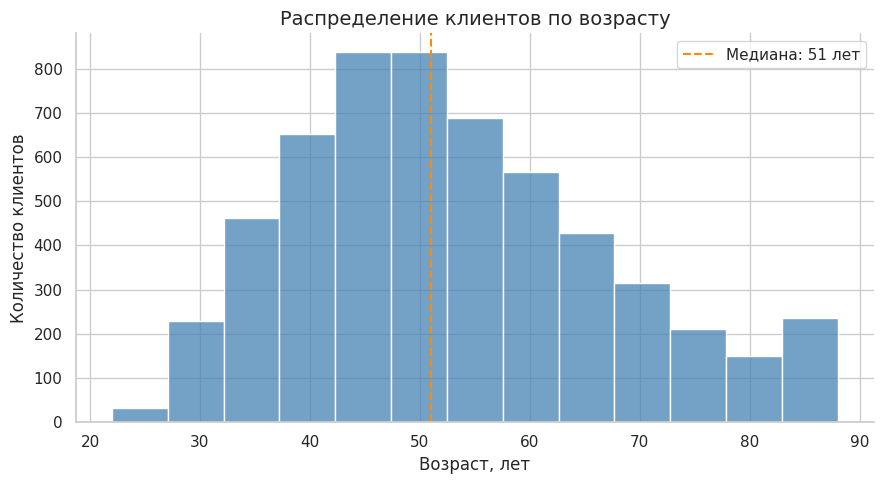

In [ ]:
# Единый стиль графиков
sns.set_theme(style="whitegrid", palette="deep")

plt.figure(figsize=(9, 5))

# Гистограмма возраста
sns.histplot(
    data=clients_clean,
    x="age",
    binwidth=5,
    color="steelblue",
    edgecolor="white"
)

# Медианный возраст
median_age = clients_clean["age"].median()

plt.axvline(
    median_age,
    color="darkorange",
    linestyle="--",
    label=f"Медиана: {median_age:.0f} лет"
)

plt.title("Распределение клиентов по возрасту", fontsize=14)
plt.xlabel("Возраст, лет")
plt.ylabel("Количество клиентов")
plt.legend()

sns.despine()
plt.tight_layout()
plt.show()



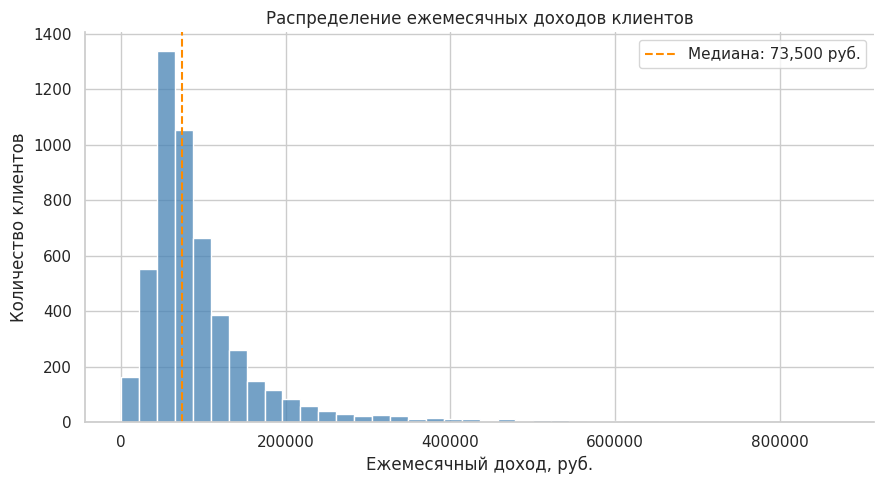

Средний доход: 94850.83
Медианный доход: 73500.0


In [ ]:

income = clients_clean["monthly_income"].dropna()

plt.figure(figsize=(9, 5))

sns.histplot(
    income,
    bins=40,
    color="steelblue",
    edgecolor="white"
)

# Медианный доход
median_income = income.median()

plt.axvline(
    median_income,
    color="darkorange",
    linestyle="--",
    label=f"Медиана: {median_income:,.0f} руб."
)

plt.title("Распределение ежемесячных доходов клиентов")
plt.xlabel("Ежемесячный доход, руб.")
plt.ylabel("Количество клиентов")
plt.legend()

sns.despine()
plt.tight_layout()
plt.show()

print("Средний доход:", round(income.mean(), 2))
print("Медианный доход:", round(income.median(), 2))


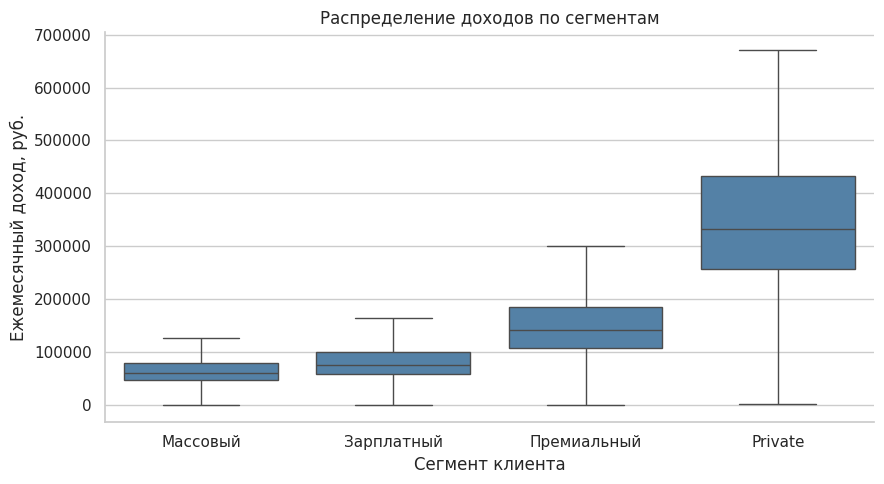

In [ ]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=clients_clean,
    x="segment",
    y="monthly_income",
    color="steelblue",
    showfliers=False
)

plt.title("Распределение доходов по сегментам")
plt.xlabel("Сегмент клиента")
plt.ylabel("Ежемесячный доход, руб.")

sns.despine()
plt.tight_layout()
plt.show()


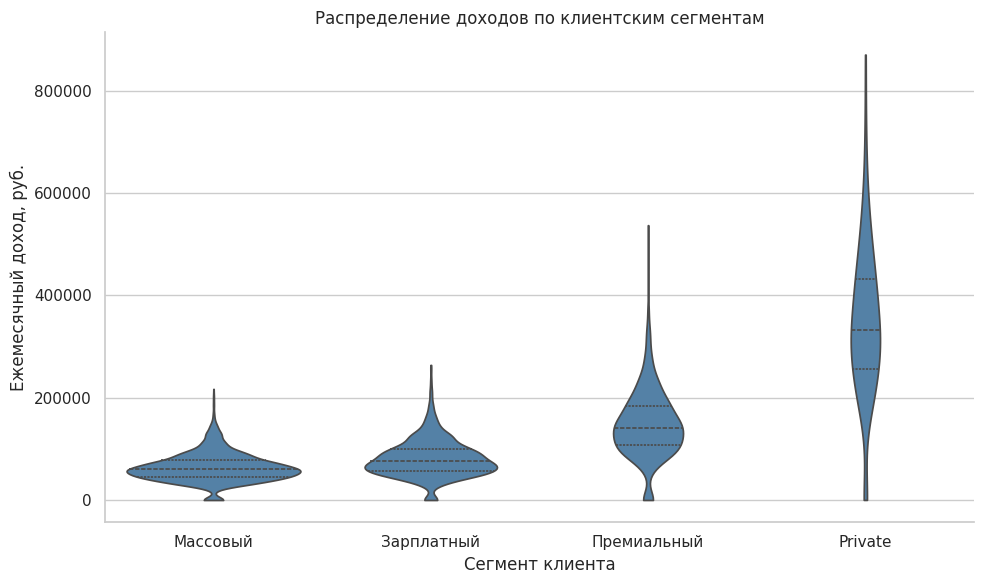

In [ ]:

plt.figure(figsize=(10, 6))

sns.violinplot(
    data=clients_clean,
    x="segment",
    y="monthly_income",
    order=["Массовый", "Зарплатный", "Премиальный", "Private"],
    color="steelblue",
    inner="quartile",
    cut=0
)

plt.title("Распределение доходов по клиентским сегментам")
plt.xlabel("Сегмент клиента")
plt.ylabel("Ежемесячный доход, руб.")

sns.despine()
plt.tight_layout()
plt.show()


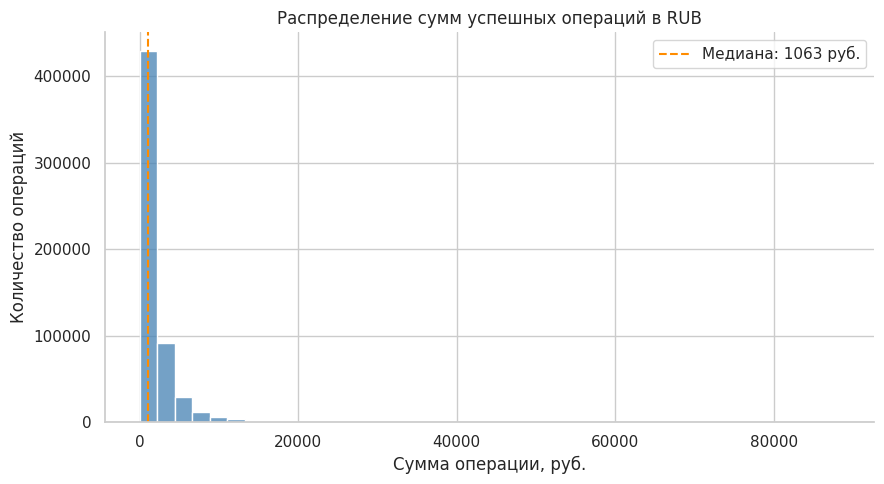

In [ ]:

# Суммы успешных операций
amount = transactions_activity.loc[
    transactions_activity["currency"] == "RUB", "amount"
]

plt.figure(figsize=(9, 5))

sns.histplot(
    amount,
    bins=40,
    color="steelblue",
    edgecolor="white"
)

plt.axvline(
    amount.median(),
    color="darkorange",
    linestyle="--",
    label=f"Медиана: {amount.median():.0f} руб."
)

plt.title("Распределение сумм успешных операций в RUB")
plt.xlabel("Сумма операции, руб.")
plt.ylabel("Количество операций")
plt.legend()

sns.despine()
plt.tight_layout()
plt.show()


### 5.2. Частотные характеристики категориальных признаков

In [ ]:

# Количество клиентов по сегментам
print("Абсолютные частоты:")
print(clients_clean["segment"].value_counts(dropna=False))

# Доля каждого сегмента
print("\nОтносительные частоты, %:")
print(
    (clients_clean["segment"].value_counts(
        normalize=True, dropna=False
    ) * 100).round(2)
)


Абсолютные частоты:
segment
Массовый       2888
Зарплатный     1570
Премиальный     965
Private         216
<NA>             10
Name: count, dtype: int64

Относительные частоты, %:
segment
Массовый       51.12
Зарплатный     27.79
Премиальный    17.08
Private         3.82
<NA>            0.18
Name: proportion, dtype: float64


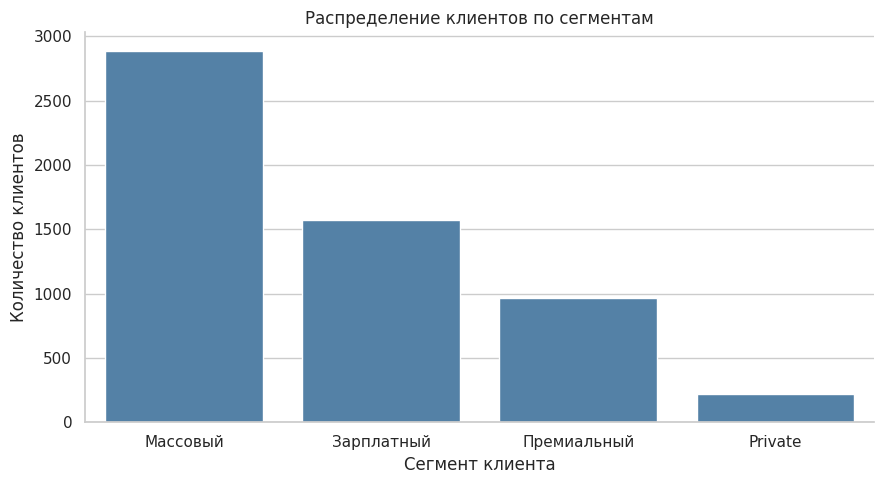

In [ ]:

plt.figure(figsize=(9, 5))

sns.countplot(
    data=clients_clean,
    x="segment",
    order=clients_clean["segment"].value_counts().index,
    color="steelblue",
    edgecolor="white"
)

plt.title("Распределение клиентов по сегментам")
plt.xlabel("Сегмент клиента")
plt.ylabel("Количество клиентов")

sns.despine()
plt.tight_layout()
plt.show()


Количество клиентов по уровням лояльности:
loyalty_tier
Базовый    2817
Серебро    1529
Золото      960
Платина     343
Name: count, dtype: int64


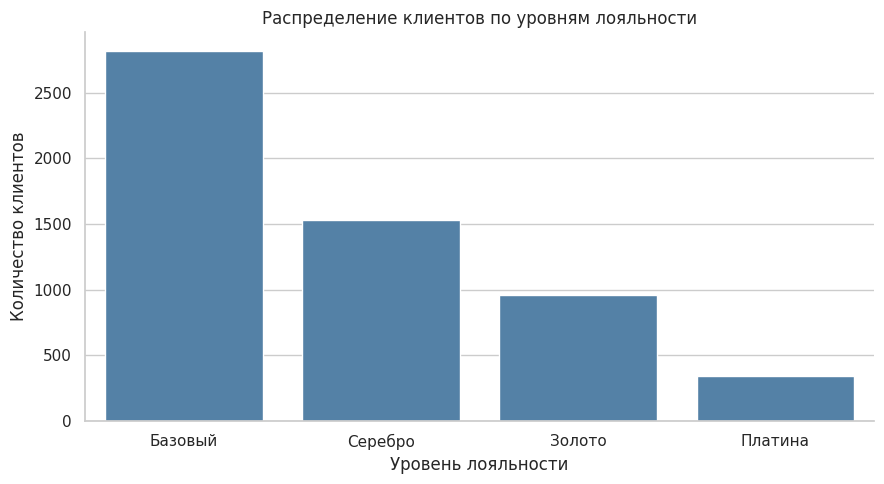

In [ ]:

print("Количество клиентов по уровням лояльности:")
print(clients_clean["loyalty_tier"].value_counts())

plt.figure(figsize=(9, 5))

sns.countplot(
    data=clients_clean,
    x="loyalty_tier",
    order=["Базовый", "Серебро", "Золото", "Платина"],
    color="steelblue",
    edgecolor="white"
)

plt.title("Распределение клиентов по уровням лояльности")
plt.xlabel("Уровень лояльности")
plt.ylabel("Количество клиентов")

sns.despine()
plt.tight_layout()
plt.show()


card_type
Дебетовая      3938
Кредитная      1242
Премиальная     469
Name: count, dtype: int64

Доли, %:
card_type
Дебетовая      69.71
Кредитная      21.99
Премиальная     8.30
Name: proportion, dtype: float64


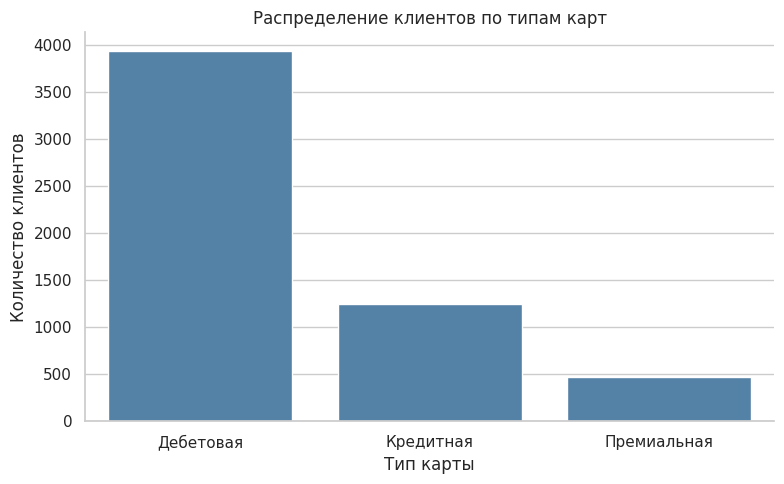

In [ ]:

# Частоты типов карт
print(clients_clean["card_type"].value_counts(dropna=False))

print("\nДоли, %:")
print(
    (clients_clean["card_type"].value_counts(
        normalize=True, dropna=False
    ) * 100).round(2)
)

# График
plt.figure(figsize=(8, 5))

sns.countplot(
    data=clients_clean,
    x="card_type",
    order=clients_clean["card_type"].value_counts().index,
    color="steelblue",
    edgecolor="white"
)

plt.title("Распределение клиентов по типам карт")
plt.xlabel("Тип карты")
plt.ylabel("Количество клиентов")

sns.despine()
plt.tight_layout()
plt.show()


In [ ]:

print("Количество операций по категориям:")
print(transactions_activity["category"].value_counts())

print("\nДоли категорий, %:")
print(
    (transactions_activity["category"].value_counts(
        normalize=True
    ) * 100).round(2)
)


Количество операций по категориям:
category
Продукты               152057
Кафе и рестораны        75262
Транспорт               66853
Одежда и обувь          58826
АЗС                     53623
Связь и интернет        44833
Развлечения и досуг     43828
Аптеки                  41493
Онлайн-сервисы          40060
Name: count, dtype: int64

Доли категорий, %:
category
Продукты               26.36
Кафе и рестораны       13.05
Транспорт              11.59
Одежда и обувь         10.20
АЗС                     9.30
Связь и интернет        7.77
Развлечения и досуг     7.60
Аптеки                  7.19
Онлайн-сервисы          6.94
Name: proportion, dtype: float64


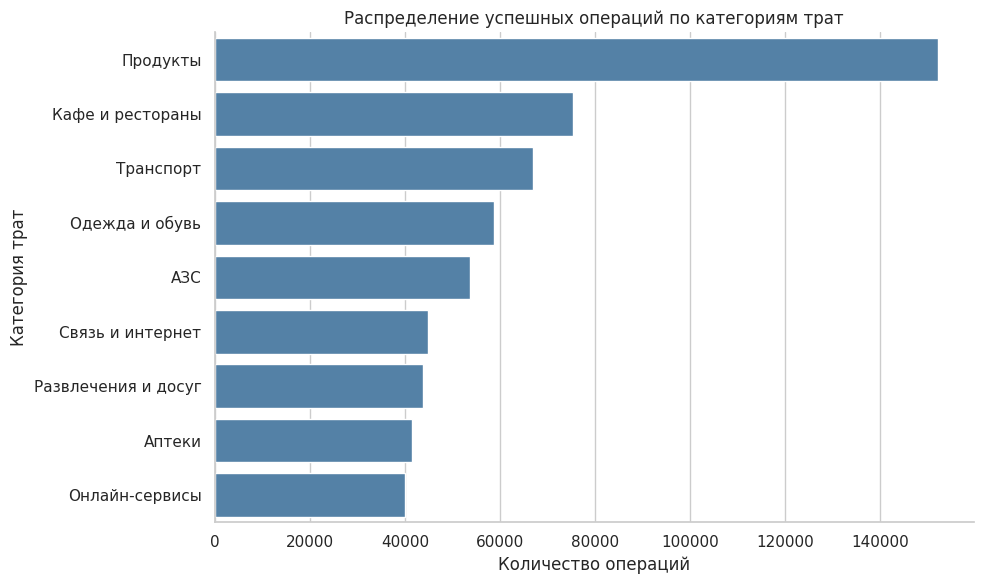

In [ ]:

plt.figure(figsize=(10, 6))

sns.countplot(
    data=transactions_activity,
    y="category",
    order=transactions_activity["category"].value_counts().index,
    color="steelblue",
    edgecolor="white"
)

plt.title("Распределение успешных операций по категориям трат")
plt.xlabel("Количество операций")
plt.ylabel("Категория трат")

sns.despine()
plt.tight_layout()
plt.show()


In [ ]:

print("Количество операций по каналам:")
print(transactions_activity["channel"].value_counts())

print("\nДоли каналов, %:")
print(
    (transactions_activity["channel"].value_counts(
        normalize=True
    ) * 100).round(2)
)


Количество операций по каналам:
channel
Карта          297838
СБП            103737
Токен           95044
Онлайн-банк     80216
Name: count, dtype: int64

Доли каналов, %:
channel
Карта          51.63
СБП            17.98
Токен          16.48
Онлайн-банк    13.91
Name: proportion, dtype: float64


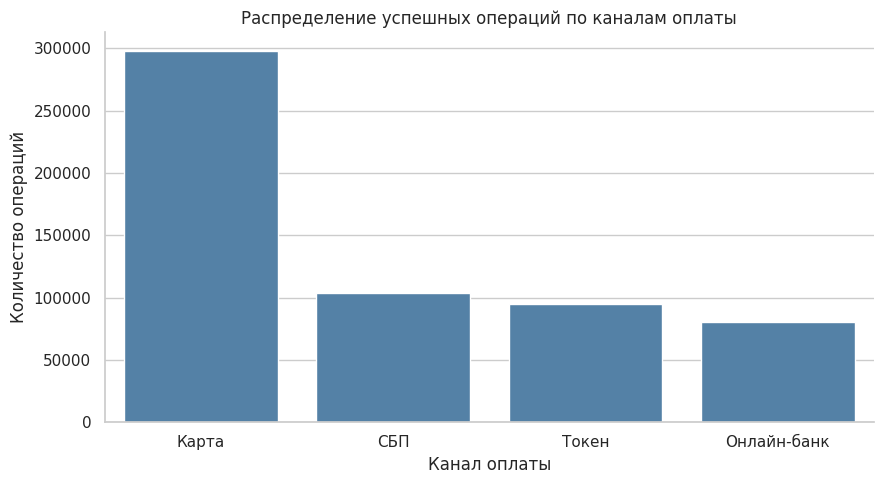

In [ ]:

plt.figure(figsize=(9, 5))

sns.countplot(
    data=transactions_activity,
    x="channel",
    order=transactions_activity["channel"].value_counts().index,
    color="steelblue",
    edgecolor="white"
)

plt.title("Распределение успешных операций по каналам оплаты")
plt.xlabel("Канал оплаты")
plt.ylabel("Количество операций")

sns.despine()
plt.tight_layout()
plt.show()


In [ ]:

# Количество уникальных клиентов по каналам оплаты
channel_clients = transactions_activity.groupby(
    "channel"
)["client_id"].nunique()

print(channel_clients.sort_values(ascending=False))


channel
Карта          5556
СБП            5308
Онлайн-банк    5247
Токен          5100
Name: client_id, dtype: int64


In [ ]:

# Количество операций по каналам
operations = transactions_activity["channel"].value_counts()

# Количество уникальных клиентов по каналам
clients_count = transactions_activity.groupby(
    "channel"
)["client_id"].nunique()

# Объединяем показатели
channel_stats = pd.DataFrame({
    "Операций": operations,
    "Клиентов": clients_count
})

# Рассчитываем доли
channel_stats["Доля операций, %"] = (
    channel_stats["Операций"] / len(transactions_activity) * 100
).round(2)

channel_stats["Охват клиентов, %"] = (
    channel_stats["Клиентов"] /
    transactions_activity["client_id"].nunique() * 100
).round(2)

display(channel_stats.sort_values("Операций", ascending=False))


,Операций,Клиентов,"Доля операций, %","Охват клиентов, %"
channel,,,,
Карта,297838,5556,51.63,98.53
СБП,103737,5308,17.98,94.13
Токен,95044,5100,16.48,90.44
Онлайн-банк,80216,5247,13.91,93.05


### 5.3. Динамика по месяцам

In [ ]:

# Создаём столбец с месяцем операции
transactions_activity["month"] = (
    transactions_activity["txn_datetime"].dt.to_period("M")
)

# Считаем операции по месяцам
monthly_txn = transactions_activity.groupby(
    "month"
).size()

# Добавляем все месяцы исследуемого периода
months = pd.period_range("2024-01", "2025-06", freq="M")
monthly_txn = monthly_txn.reindex(months, fill_value=0)

display(monthly_txn)


2024-01    24495
2024-02    30434
2024-03    34753
2024-04    34338
2024-05    31338
2024-06    33830
2024-07    35079
2024-08    36271
2024-09    34342
2024-10    35296
2024-11    34971
2024-12    43877
2025-01    22606
2025-02    27540
2025-03    30192
2025-04    29222
2025-05    27800
2025-06    30451
Freq: M, dtype: int64

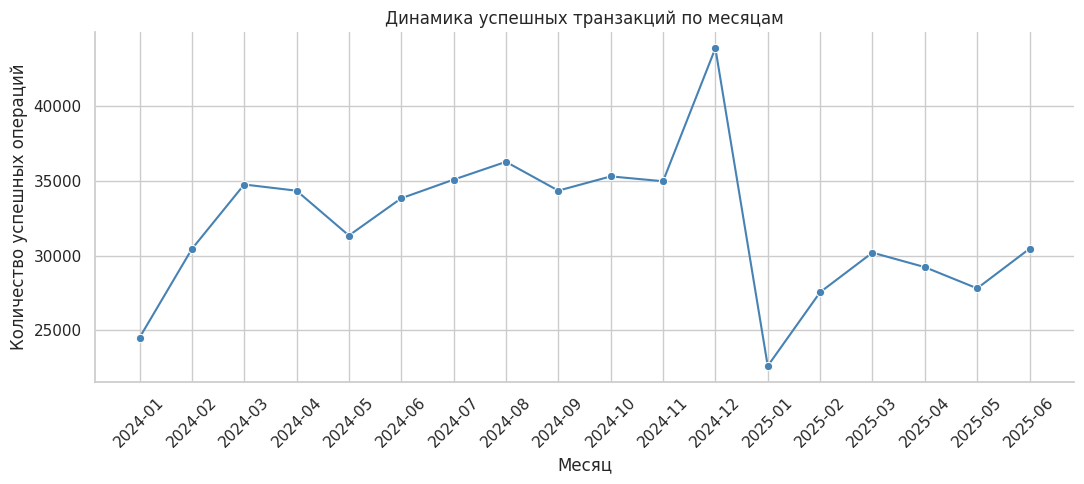

In [ ]:

plt.figure(figsize=(11, 5))

sns.lineplot(
    x=monthly_txn.index.astype(str),
    y=monthly_txn.values,
    marker="o",
    color="steelblue"
)

plt.title("Динамика успешных транзакций по месяцам")
plt.xlabel("Месяц")
plt.ylabel("Количество успешных операций")

plt.xticks(rotation=45)
sns.despine()
plt.tight_layout()
plt.show()


In [ ]:

# Среднемесячное количество операций
avg_2024 = monthly_txn.loc["2024"].mean()
avg_2025 = monthly_txn.loc["2025"].mean()

# Изменение в процентах
change = (avg_2025 / avg_2024 - 1) * 100

print("Среднемесячное количество операций в 2024:",
      round(avg_2024, 2))

print("Среднемесячное количество операций в 2025:",
      round(avg_2025, 2))

print("Изменение, %:", round(change, 2))


Среднемесячное количество операций в 2024: 34085.33
Среднемесячное количество операций в 2025: 27968.5
Изменение, %: -17.95


,2024,2025
Янв,24495,22606
Фев,30434,27540
Мар,34753,30192
Апр,34338,29222
Май,31338,27800
Июн,33830,30451


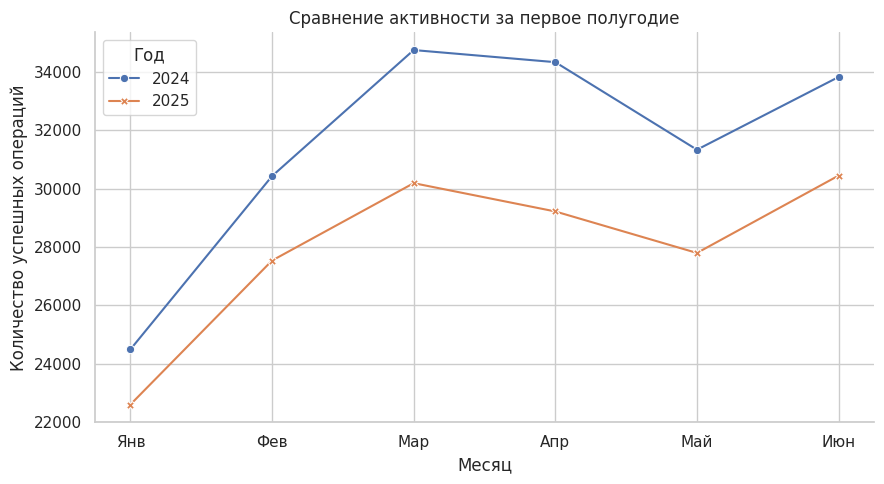

In [ ]:

# Сравниваем одинаковые месяцы
monthly_compare = pd.DataFrame({
    "2024": monthly_txn.loc["2024-01":"2024-06"].values,
    "2025": monthly_txn.loc["2025-01":"2025-06"].values
}, index=["Янв", "Фев", "Мар", "Апр", "Май", "Июн"])

display(monthly_compare)

# Строим график
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=monthly_compare,
    markers=True,
    dashes=False
)

plt.title("Сравнение активности за первое полугодие")
plt.xlabel("Месяц")
plt.ylabel("Количество успешных операций")
plt.legend(title="Год")

sns.despine()
plt.tight_layout()
plt.show()


In [ ]:

avg_2024_h1 = monthly_compare["2024"].mean()
avg_2025_h1 = monthly_compare["2025"].mean()

change_h1 = (avg_2025_h1 / avg_2024_h1 - 1) * 100

print("Изменение между первыми полугодиями, %:",
      round(change_h1, 2))


Изменение между первыми полугодиями, %: -11.3


### 5.4. Разрезы и связи между признаками

In [ ]:

# Добавляем сегмент к транзакциям
txn_segments = transactions_activity.merge(
    clients_clean[["client_id", "segment"]],
    on="client_id",
    how="left"
)

# Определяем год операции
txn_segments["year"] = txn_segments["txn_datetime"].dt.year

# Количество операций по сегментам и годам
segment_year = pd.crosstab(
    txn_segments["segment"],
    txn_segments["year"]
)

# Учитываем разную продолжительность периодов
segment_year[2024] = segment_year[2024] / 12
segment_year[2025] = segment_year[2025] / 6

# Рассчитываем изменение
segment_year["Изменение, %"] = (
    (segment_year[2025] / segment_year[2024] - 1) * 100
).round(2)

display(segment_year.round(2))


year,2024,2025,"Изменение, %"
segment,,,
Private,1573.42,1457.83,-7.35
Зарплатный,10199.67,9455.67,-7.29
Массовый,15319.33,10420.00,-31.98
Премиальный,6929.58,6578.50,-5.07


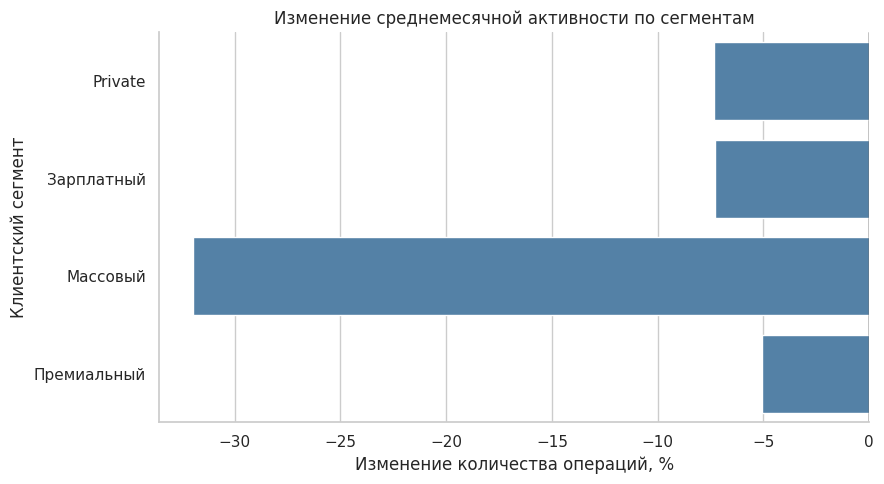

In [ ]:

# Подготавливаем данные
plot_data = segment_year.reset_index()

plt.figure(figsize=(9, 5))

sns.barplot(
    data=plot_data,
    x="Изменение, %",
    y="segment",
    color="steelblue"
)

plt.axvline(0, color="black", linewidth=1)

plt.title("Изменение среднемесячной активности по сегментам")
plt.xlabel("Изменение количества операций, %")
plt.ylabel("Клиентский сегмент")

sns.despine()
plt.tight_layout()
plt.show()


In [ ]:

# Разделяем операции по годам
txn_2024 = transactions_activity[
    transactions_activity["txn_datetime"].dt.year == 2024
]

txn_2025 = transactions_activity[
    transactions_activity["txn_datetime"].dt.year == 2025
]

# Количество операций на каждого клиента
n_2024 = txn_2024.groupby("client_id").size()
n_2025 = txn_2025.groupby("client_id").size()

# Формируем таблицу клиентов
client_metrics = clients_clean[["client_id", "segment"]].copy()

client_metrics["n_2024"] = (
    client_metrics["client_id"].map(n_2024).fillna(0)
)

client_metrics["n_2025"] = (
    client_metrics["client_id"].map(n_2025).fillna(0)
)

# Рассчитываем среднемесячную активность
client_metrics["freq_2024"] = client_metrics["n_2024"] / 12
client_metrics["freq_2025"] = client_metrics["n_2025"] / 6

display(client_metrics.head())


,client_id,segment,n_2024,n_2025,freq_2024,freq_2025
0,C001917,Массовый,142.0,60.0,11.833333,10.000000
1,C004159,Зарплатный,57.0,37.0,4.750000,6.166667
2,C003190,Зарплатный,191.0,81.0,15.916667,13.500000
3,C005429,Массовый,39.0,14.0,3.250000,2.333333
4,C002266,Массовый,35.0,12.0,2.916667,2.000000


In [ ]:
# Средний чек анализируем только для операций в RUB
# (суммы в разных валютах нельзя усреднять без пересчёта по курсу)
txn_2024_rub = txn_2024[txn_2024["currency"] == "RUB"]
txn_2025_rub = txn_2025[txn_2025["currency"] == "RUB"]

check_2024 = txn_2024_rub.groupby("client_id")["amount"].mean()
check_2025 = txn_2025_rub.groupby("client_id")["amount"].mean()

client_metrics["avg_check_2024"] = client_metrics["client_id"].map(check_2024)
client_metrics["avg_check_2025"] = client_metrics["client_id"].map(check_2025)

display(client_metrics.head())

,client_id,segment,n_2024,n_2025,freq_2024,freq_2025,avg_check_2024,avg_check_2025
0,C001917,Массовый,142.0,60.0,11.833333,10.000000,1401.548369,2217.525333
1,C004159,Зарплатный,57.0,37.0,4.750000,6.166667,2085.083860,1562.073514
2,C003190,Зарплатный,191.0,81.0,15.916667,13.500000,2137.751099,1817.124304
3,C005429,Массовый,39.0,14.0,3.250000,2.333333,1165.916923,1715.555714
4,C002266,Массовый,35.0,12.0,2.916667,2.000000,1026.350571,1343.665833


In [ ]:
# Средняя активность — по всем клиентам сегмента, в том числе с нулём операций.
# Средний чек (только RUB) — среди клиентов, у которых он определён.
segment_metrics = client_metrics.groupby("segment")[[
    "freq_2024", "freq_2025", "avg_check_2024", "avg_check_2025"
]].mean()

display(segment_metrics.round(2))

,freq_2024,freq_2025,avg_check_2024,avg_check_2025
segment,,,,
Private,7.28,6.75,3419.29,3445.46
Зарплатный,6.50,6.02,1764.87,1616.05
Массовый,5.30,3.61,1521.24,1482.58
Премиальный,7.18,6.82,2451.58,2488.29


In [ ]:
# Суммарные расходы также считаем только в RUB
sum_2024 = txn_2024_rub.groupby("client_id")["amount"].sum()
sum_2025 = txn_2025_rub.groupby("client_id")["amount"].sum()

client_metrics["spend_2024"] = (
    client_metrics["client_id"].map(sum_2024).fillna(0) / 12
)
client_metrics["spend_2025"] = (
    client_metrics["client_id"].map(sum_2025).fillna(0) / 6
)

display(client_metrics.head())

,client_id,segment,n_2024,n_2025,freq_2024,freq_2025,avg_check_2024,avg_check_2025,spend_2024,spend_2025
0,C001917,Массовый,142.0,60.0,11.833333,10.000000,1401.548369,2217.525333,16468.193333,22175.253333
1,C004159,Зарплатный,57.0,37.0,4.750000,6.166667,2085.083860,1562.073514,9904.148333,9632.786667
2,C003190,Зарплатный,191.0,81.0,15.916667,13.500000,2137.751099,1817.124304,34025.871667,23925.470000
3,C005429,Массовый,39.0,14.0,3.250000,2.333333,1165.916923,1715.555714,3789.230000,4002.963333
4,C002266,Массовый,35.0,12.0,2.916667,2.000000,1026.350571,1343.665833,2993.522500,2687.331667


In [ ]:

# Количество операций по категориям и годам
category_year = pd.crosstab(
    transactions_activity["category"],
    transactions_activity["txn_datetime"].dt.year
)

# Среднемесячные значения
category_year["2024/мес"] = category_year[2024] / 12
category_year["2025/мес"] = category_year[2025] / 6

# Изменение активности
category_year["Изменение, %"] = (
    category_year["2025/мес"] /
    category_year["2024/мес"] - 1
) * 100

display(
    category_year[
        ["2024/мес", "2025/мес", "Изменение, %"]
    ].sort_values("Изменение, %").round(2)
)


txn_datetime,2024/мес,2025/мес,"Изменение, %"
category,,,
Транспорт,4192.17,2757.83,-34.21
Аптеки,2456.17,2003.17,-18.44
Продукты,8991.33,7360.17,-18.14
Онлайн-сервисы,2360.00,1956.67,-17.09
Связь и интернет,2637.33,2197.50,-16.68
АЗС,3124.92,2687.33,-14.00
Одежда и обувь,3425.33,2953.67,-13.77
Кафе и рестораны,4367.92,3807.83,-12.82
Развлечения и досуг,2530.17,2244.33,-11.30


In [ ]:

# Количество операций по каналам и годам
channel_year = pd.crosstab(
    transactions_activity["channel"],
    transactions_activity["txn_datetime"].dt.year
)

channel_year["2024/мес"] = channel_year[2024] / 12
channel_year["2025/мес"] = channel_year[2025] / 6

channel_year["Изменение, %"] = (
    channel_year["2025/мес"] /
    channel_year["2024/мес"] - 1
) * 100

display(
    channel_year[
        ["2024/мес", "2025/мес", "Изменение, %"]
    ].sort_values("Изменение, %").round(2)
)


txn_datetime,2024/мес,2025/мес,"Изменение, %"
channel,,,
Онлайн-банк,4995.83,3377.67,-32.39
Карта,18226.33,13187.00,-27.65
СБП,6102.58,5084.33,-16.69
Токен,4760.58,6319.50,32.75


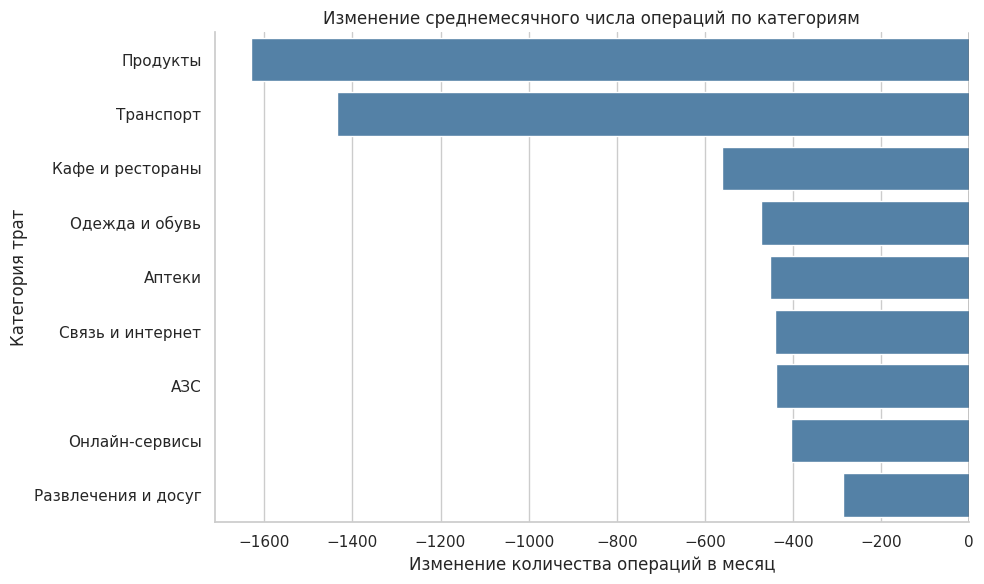

In [ ]:

# Абсолютное изменение активности
category_year["Изменение, шт./мес"] = (
    category_year["2025/мес"] - category_year["2024/мес"]
)

# Подготавливаем данные
plot_data = category_year.reset_index()
plot_data = plot_data.sort_values("Изменение, шт./мес")

plt.figure(figsize=(10, 6))

sns.barplot(
    data=plot_data,
    x="Изменение, шт./мес",
    y="category",
    color="steelblue"
)

plt.axvline(0, color="black", linewidth=1)

plt.title("Изменение среднемесячного числа операций по категориям")
plt.xlabel("Изменение количества операций в месяц")
plt.ylabel("Категория трат")

sns.despine()
plt.tight_layout()
plt.show()


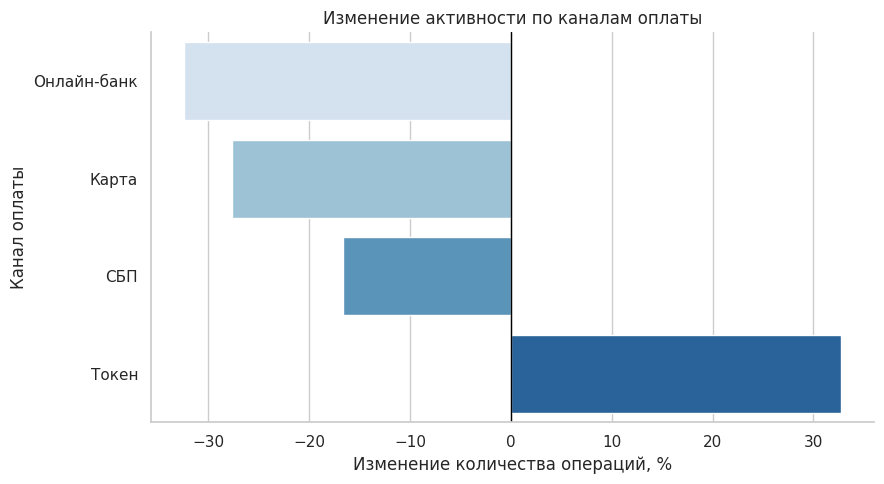

In [ ]:

plot_data = channel_year.reset_index()
plot_data = plot_data.sort_values("Изменение, %")

plt.figure(figsize=(9, 5))

sns.barplot(
    data=plot_data,
    x="Изменение, %",
    y="channel",
    hue="channel",
    palette="Blues",
    legend=False
)

plt.axvline(0, color="black", linewidth=1)

plt.title("Изменение активности по каналам оплаты")
plt.xlabel("Изменение количества операций, %")
plt.ylabel("Канал оплаты")

sns.despine()
plt.tight_layout()
plt.show()


## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

In [ ]:

# Абсолютное изменение операций в месяц
client_metrics["change_abs"] = (
    client_metrics["freq_2025"] - client_metrics["freq_2024"]
)

# Относительное изменение в процентах
client_metrics["change_pct"] = (
    client_metrics["freq_2025"] /
    client_metrics["freq_2024"].replace(0, float("nan")) - 1
) * 100

display(client_metrics[
    ["client_id", "freq_2024", "freq_2025",
     "change_abs", "change_pct"]
].head(10).round(2))


,client_id,freq_2024,freq_2025,change_abs,change_pct
0,C001917,11.83,10.00,-1.83,-15.49
1,C004159,4.75,6.17,1.42,29.82
2,C003190,15.92,13.50,-2.42,-15.18
3,C005429,3.25,2.33,-0.92,-28.21
4,C002266,2.92,2.00,-0.92,-31.43
5,C004725,3.00,3.33,0.33,11.11
6,C003707,4.92,8.50,3.58,72.88
7,C003789,0.50,1.00,0.50,100.00
8,C004555,8.42,7.33,-1.08,-12.87
9,C000232,4.83,7.67,2.83,58.62


In [ ]:

print("Клиентов со снижением:",
      (client_metrics["change_abs"] < 0).sum())

print("Клиентов с ростом:",
      (client_metrics["change_abs"] > 0).sum())

print("Без изменения:",
      (client_metrics["change_abs"] == 0).sum())

print("Нулевая активность в 2024:",
      (client_metrics["freq_2024"] == 0).sum())


Клиентов со снижением: 3543
Клиентов с ростом: 2028
Без изменения: 78
Нулевая активность в 2024: 402


In [ ]:

# Клиенты без активности в 2024 году
zero_2024 = client_metrics[
    client_metrics["freq_2024"] == 0
]

print("Всего:", len(zero_2024))

print("Появилась активность в 2025:",
      (zero_2024["freq_2025"] > 0).sum())

print("Нет активности в обоих периодах:",
      (zero_2024["freq_2025"] == 0).sum())


Всего: 402
Появилась активность в 2025: 392
Нет активности в обоих периодах: 10


In [ ]:

zero_2024 = zero_2024.merge(
    clients_clean[["client_id", "registration_date"]],
    on="client_id",
    how="left"
)

print("Зарегистрировались в 2025:",
      (zero_2024["registration_date"] >= "2025-01-01").sum())


Зарегистрировались в 2025: 9


In [ ]:

print(
    clients_clean["registration_date"]
    .dt.year
    .value_counts()
    .sort_index()
)


registration_date
2010     57
2011    132
2012    249
2013    346
2014    474
2015    541
2016    645
2017    583
2018    552
2019    609
2020    499
2021    366
2022    277
2023    180
2024    130
2025      9
Name: count, dtype: int64


In [ ]:

registered_2024 = clients_clean[
    (clients_clean["registration_date"] >= "2024-01-01") &
    (clients_clean["registration_date"] < "2025-01-01")
]

print("Зарегистрировались в 2024 году:",
      len(registered_2024))

print("\nПо месяцам:")
print(
    registered_2024["registration_date"]
    .dt.month
    .value_counts()
    .sort_index()
)


Зарегистрировались в 2024 году: 130

По месяцам:
registration_date
1     16
2     10
3     11
4     22
5      7
6     15
7     11
8     14
9      6
10     7
11     8
12     3
Name: count, dtype: int64


In [ ]:

# Добавляем дату регистрации в таблицу метрик
client_metrics["registration_date"] = client_metrics["client_id"].map(
    clients_clean.set_index("client_id")["registration_date"]
)

# Клиенты с полным базовым периодом
client_metrics["full_period"] = (
    client_metrics["registration_date"] <= "2024-01-01"
)

print("Всего клиентов:", len(client_metrics))
print("С полным периодом:", client_metrics["full_period"].sum())
print("С неполным периодом:", (~client_metrics["full_period"]).sum())


Всего клиентов: 5649
С полным периодом: 5512
С неполным периодом: 137


In [ ]:

# ЭТАП 1: общий отбор. Одновременно минимум 30% и 2 операции/мес.
# Порог 1 операция/мес. ниже относится ТОЛЬКО к категории или каналу.
# Определяем существенное снижение
client_metrics["significant_decline"] = (
    client_metrics["full_period"] &
    (client_metrics["freq_2024"] > 0) &
    (client_metrics["change_pct"] <= -30) &
    (client_metrics["change_abs"] <= -2)
)

print("Клиентов с любым снижением:",
      (client_metrics["change_abs"] < 0).sum())

print("Клиентов с существенным снижением:",
      client_metrics["significant_decline"].sum())


Клиентов с любым снижением: 3543
Клиентов с существенным снижением: 1523


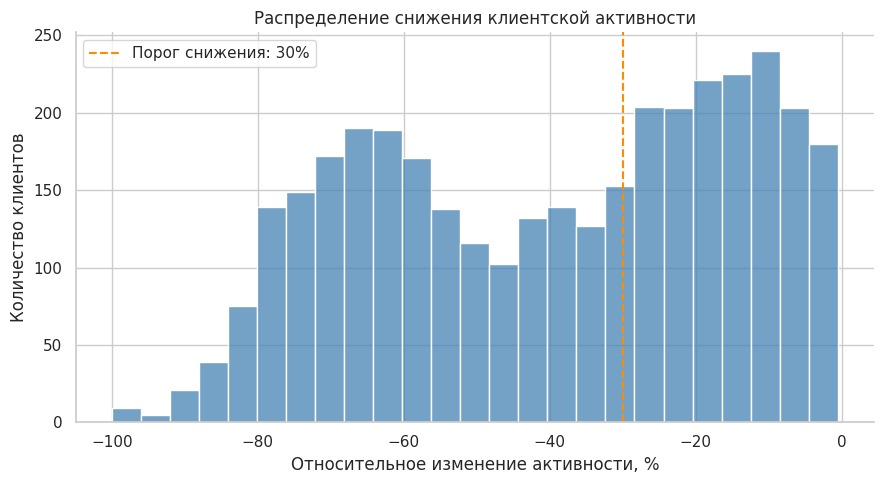

In [ ]:

# Клиенты со снижением и полным периодом
declining = client_metrics[
    client_metrics["full_period"] &
    (client_metrics["change_abs"] < 0)
]

plt.figure(figsize=(9, 5))

sns.histplot(
    data=declining,
    x="change_pct",
    bins=25,
    color="steelblue",
    edgecolor="white"
)

plt.axvline(
    -30,
    color="darkorange",
    linestyle="--",
    label="Порог снижения: 30%"
)

plt.title("Распределение снижения клиентской активности")
plt.xlabel("Относительное изменение активности, %")
plt.ylabel("Количество клиентов")
plt.legend()

sns.despine()
plt.tight_layout()
plt.show()


### Вывод по разделу 6

**Метрика активности** — количество **успешных** транзакций клиента в месяц независимо от канала оплаты и валюты операции. Для базового периода частота равна `n_2024 / 12` (январь–декабрь 2024 года), для оцениваемого — `n_2025 / 6` (январь–июнь 2025 года). Считались только операции клиентов, представленных в очищенном справочнике, но клиенты с нулём операций также оставлены в знаменателе клиентских сравнений.

Всего сокращение активности обнаружено у 3543 клиентов. Для последующего отбора использованы клиенты, зарегистрированные не позднее 01.01.2024 (5512 человек): иначе базовый период был бы неполным. **Существенное снижение** — одновременно не менее 30% и не менее 2 операций в месяц относительно 2024 года, при положительной активности в базовом периоде. Таких клиентов — 1523. Проверка альтернативных порогов показывает, что численность кандидатов чувствительна к выбору границы.

Метрика не отражает отдельное снижение **денежного объёма** покупок или **среднего чека**, если их количество не изменилось. Также она не показывает причину отказа от операций или перехода в другой банк. Для уточнения характера изменений дополнительно анализируются категории покупок и платёжные каналы; это описательные закономерности, а не доказанные причины.

## 7. Формирование маркетинговых групп

**Двухэтапный отбор (условия применяются одновременно):**

1. **Общий фильтр кандидатов:** полный базовый период, ненулевая активность в 2024 году и сокращение **всех успешных операций клиента не менее чем на 30% и не менее чем на 2 операции в месяц**. Для кампании также обязательно согласие на коммуникацию.
2. **Дополнительное тематическое правило группы:** принадлежность к массовому или зарплатному сегменту, уменьшение операций **в конкретной категории «Продукты» либо канале «Карта» минимум на 1 операцию в месяц**, причём это уменьшение должно составлять **не менее 30% общего чистого сокращения**.

Таким образом, **1 операция в месяц не заменяет порог 2 операции в месяц**: первое значение относится только к выбранной категории или каналу, второе — ко всей активности клиента. Предварительные тематические правила могут пересекаться, но итоговый список содержит каждого клиента только один раз.

In [ ]:

# Выбираем кандидатов
candidates = client_metrics[
    client_metrics["significant_decline"]
]

print("Количество кандидатов:", len(candidates))

# Операции этих клиентов
candidate_txn = transactions_activity[
    transactions_activity["client_id"].isin(candidates["client_id"])
].copy()

print("Количество операций кандидатов:", len(candidate_txn))


Количество кандидатов: 1523
Количество операций кандидатов: 161177


In [ ]:

# Год операции
candidate_txn["year"] = candidate_txn["txn_datetime"].dt.year

# Количество операций по категориям и годам
category_decline = pd.crosstab(
    candidate_txn["category"],
    candidate_txn["year"]
)

# Добавляем оба года
category_decline = category_decline.reindex(
    columns=[2024, 2025], fill_value=0
)

# Среднемесячная частота
category_decline["2024/мес"] = category_decline[2024] / 12
category_decline["2025/мес"] = category_decline[2025] / 6

# Абсолютное сокращение
category_decline["Снижение/мес"] = (
    category_decline["2024/мес"] -
    category_decline["2025/мес"]
)

display(
    category_decline[
        ["2024/мес", "2025/мес", "Снижение/мес"]
    ].sort_values("Снижение/мес", ascending=False).round(2)
)


year,2024/мес,2025/мес,Снижение/мес
category,,,
Продукты,3066.92,1227.00,1839.92
Транспорт,1493.58,433.00,1060.58
Кафе и рестораны,1286.92,570.17,716.75
Одежда и обувь,1060.67,470.50,590.17
АЗС,961.33,417.33,544.00
Связь и интернет,910.42,375.67,534.75
Аптеки,866.33,357.17,509.17
Онлайн-сервисы,772.17,317.00,455.17
Развлечения и досуг,763.00,332.33,430.67


In [ ]:

# Количество операций по каналам и годам
channel_decline = pd.crosstab(
    candidate_txn["channel"],
    candidate_txn["year"]
)

channel_decline = channel_decline.reindex(
    columns=[2024, 2025], fill_value=0
)

# Среднемесячное количество операций
channel_decline["2024/мес"] = channel_decline[2024] / 12
channel_decline["2025/мес"] = channel_decline[2025] / 6

# Изменение активности
channel_decline["Снижение/мес"] = (
    channel_decline["2024/мес"] -
    channel_decline["2025/мес"]
)

display(
    channel_decline[
        ["2024/мес", "2025/мес", "Снижение/мес"]
    ].sort_values("Снижение/мес", ascending=False).round(2)
)


year,2024/мес,2025/мес,Снижение/мес
channel,,,
Карта,5764.50,2259.50,3505.00
СБП,2034.33,836.50,1197.83
Онлайн-банк,1767.17,591.00,1176.17
Токен,1615.33,813.17,802.17


In [ ]:

# Добавляем согласие на коммуникацию
candidates = candidates.merge(
    clients_clean[["client_id", "marketing_opt_in"]],
    on="client_id",
    how="left"
)

print("Всего кандидатов:", len(candidates))
print(candidates["marketing_opt_in"].value_counts(dropna=False))

# Оставляем клиентов с согласием
candidates = candidates[
    candidates["marketing_opt_in"] == "Да"
].copy()

print("Доступно для кампании:", len(candidates))


Всего кандидатов: 1523
marketing_opt_in
Да     1359
Нет     164
Name: count, dtype: int64
Доступно для кампании: 1359


In [ ]:

# Считаем снижение по двум направлениям
for name, column, value in [
    ("food", "category", "Продукты"),
    ("card", "channel", "Карта")
]:
    data = candidate_txn[candidate_txn[column] == value]

    n24 = data[data["year"] == 2024].groupby("client_id").size()
    n25 = data[data["year"] == 2025].groupby("client_id").size()

    candidates[name + "_loss"] = (
        candidates["client_id"].map(n24).fillna(0) / 12
        - candidates["client_id"].map(n25).fillna(0) / 6
    )

# Общее снижение операций в месяц
candidates["total_loss"] = -candidates["change_abs"]

# Доля снижения, приходящаяся на каждое направление
candidates["food_share"] = (
    candidates["food_loss"] / candidates["total_loss"]
)

candidates["card_share"] = (
    candidates["card_loss"] / candidates["total_loss"]
)


In [ ]:

# ЭТАП 2: тематические признаки применяются только к candidates,
# которые УЖЕ прошли общий порог: >= 30% и >= 2 операции/мес.
# Здесь >= 1 означает потерю в конкретной категории/канале, не в целом.
# Кандидаты на включение по продуктовому признаку
food_group = (
    (candidates["segment"] == "Массовый") &
    (candidates["food_loss"] >= 1) &
    (candidates["food_share"] >= 0.30)
)

# Кандидаты на включение по карточному признаку
card_group = (
    (candidates["segment"] == "Массовый") &
    (candidates["card_loss"] >= 1) &
    (candidates["card_share"] >= 0.30)
)

print("Подходят для продуктовой группы:", food_group.sum())
print("Подходят для карточной группы:", card_group.sum())
print("Подходят для обеих:", (food_group & card_group).sum())


Подходят для продуктовой группы: 405
Подходят для карточной группы: 723
Подходят для обеих: 310


In [ ]:

for name, column, value in [
    ("food", "category", "Продукты"),
    ("card", "channel", "Карта")
]:
    data = candidate_txn[candidate_txn[column] == value]

    n24 = data[data["year"] == 2024].groupby("client_id").size()
    n25 = data[data["year"] == 2025].groupby("client_id").size()

    base = candidates["client_id"].map(n24).fillna(0) / 12
    current = candidates["client_id"].map(n25).fillna(0) / 6

    candidates[name + "_decline_pct"] = (
        (1 - current / base.replace(0, float("nan"))) * 100
    )


In [ ]:

food_final = (
    food_group &
    (
        ~card_group |
        (candidates["food_decline_pct"] >= candidates["card_decline_pct"])
    )
)

card_final = (
    card_group &
    ~food_final
)

print("Продуктовая группа:", food_final.sum())
print("Карточная группа:", card_final.sum())
print("Пересечений:", (food_final & card_final).sum())


Продуктовая группа: 333
Карточная группа: 485
Пересечений: 0


In [ ]:

# Создаём итоговые группы
candidates["group"] = pd.NA

candidates.loc[food_final, "group"] = "Продуктовая"
candidates.loc[card_final, "group"] = "Карточная"

# Третья группа: тот же дополнительный тематический порог 1 операция/мес.
# Общий порог 2 операции/мес. уже проверен при создании candidates.
# Третья группа
salary_final = (
    (candidates["segment"] == "Зарплатный") &
    (candidates["card_loss"] >= 1) &
    (candidates["card_share"] >= 0.30)
)

candidates.loc[salary_final, "group"] = "Зарплатная"

print("Количество клиентов по группам:")
print(candidates["group"].value_counts(dropna=False))


Количество клиентов по группам:
group
Карточная      485
<NA>           360
Продуктовая    333
Зарплатная     181
Name: count, dtype: int64


In [ ]:
# Формируем список только по окончательному распределению
campaign = candidates.loc[
    candidates["group"].notna(),
    ["client_id", "group"]
].copy()

# Проверяем требования задания
counts = campaign["group"].value_counts()
print("Распределение по группам:")
print(counts)
print("Всего участников:", len(campaign))

assert campaign["client_id"].is_unique
assert campaign["client_id"].notna().all()
assert len(campaign) <= 2000
assert 3 <= campaign["group"].nunique() <= 5
assert (counts >= 150).all()
assert campaign["client_id"].isin(candidates["client_id"]).all()
assert campaign["client_id"].map(
    clients_clean.set_index("client_id")["marketing_opt_in"]
).eq("Да").all()

print("Проверки успешно пройдены")

Распределение по группам:
group
Карточная      485
Продуктовая    333
Зарплатная     181
Name: count, dtype: int64
Всего участников: 999
Проверки успешно пройдены


### 7.1. Кого в кампанию не берём и почему

In [ ]:

# Берём всех клиентов
selection = client_metrics[
    ["client_id", "full_period", "significant_decline"]
].copy()

# Добавляем согласие на коммуникацию
selection["marketing_opt_in"] = selection["client_id"].map(
    clients_clean.set_index("client_id")["marketing_opt_in"]
)

# Проверяем участие в кампании
selection["in_campaign"] = (
    selection["client_id"].isin(campaign["client_id"])
)

# Изначально считаем, что клиент включён
selection["reason"] = "В кампании"

# Недостаточная история
selection.loc[
    ~selection["full_period"], "reason"
] = "Недостаточная история"

# Нет существенного снижения
selection.loc[
    selection["full_period"] &
    ~selection["significant_decline"], "reason"
] = "Нет существенного снижения"

# Нет согласия
selection.loc[
    selection["significant_decline"] &
    (selection["marketing_opt_in"] != "Да"), "reason"
] = "Нет согласия"

# Не подходит под выбранные группы
selection.loc[
    selection["significant_decline"] &
    (selection["marketing_opt_in"] == "Да") &
    ~selection["in_campaign"], "reason"
] = "Не подходит под правила групп"

display(selection["reason"].value_counts())


# Каждому клиенту назначена ровно одна причина или участие
assert selection["client_id"].is_unique
assert len(selection) == len(clients_clean)
assert (selection["in_campaign"] == selection["reason"].eq("В кампании")).all()
assert selection["reason"].notna().all()
print("Полнота распределения проверена")


reason
Нет существенного снижения       3989
В кампании                        999
Не подходит под правила групп     360
Нет согласия                      164
Недостаточная история             137
Name: count, dtype: int64

Полнота распределения проверена


### Вывод по разделу 7. Формирование маркетинговых групп

На основании анализа транзакционной активности сформированы **три непересекающиеся группы общей численностью 999 клиентов**. Отбор выполнялся в два этапа. **Сначала** оставлены клиенты с полным базовым периодом и согласием на коммуникации, у которых **общее** среднемесячное число успешных операций сократилось одновременно **не менее чем на 30% и не менее чем на 2 операции**. **Затем** проверено дополнительное тематическое условие: сокращение числа операций **в отдельной категории или канале минимум на 1 операцию в месяц** и вклад этого направления **не менее 30% общего снижения**. Это **разные пороги**, выполняющиеся одновременно.

**1. Продуктовая группа (333 клиента):** массовый сегмент; после прохождения общего фильтра обнаружено сокращение покупок продуктов как минимум на 1 операцию в месяц, с вкладом категории «Продукты» не менее 30% общего чистого снижения. В группе число продуктовых покупок в среднем по совокупности сократилось примерно на 75%. Возможное предложение — стимулирование повседневных продуктовых покупок.

**2. Карточная группа (485 клиентов):** массовый сегмент; после прохождения общего фильтра количество операций через канал «Карта» сократилось минимум на 1 в месяц, вклад канала — не менее 30% общего чистого снижения. Среднее число операций картой уменьшилось с 4,18 до 1,43 в месяц (около 66%). Возможное предложение — возвращение к оплате пластиковой картой.

**3. Зарплатная группа (181 клиент):** зарплатный сегмент; выполнены тот же общий фильтр и дополнительное тематическое условие по каналу «Карта». Среднее число таких операций уменьшилось с 4,80 до 1,90 в месяц (около 60,5%). Коммуникация может учитывать особенности зарплатного обслуживания.

При пересечении продуктового и карточного правил в массовом сегменте клиент отнесён к группе, где **относительное снижение внутри соответствующего направления** выражено сильнее; при равенстве приоритет дан продуктовой группе. Вклад категории и канала может относиться к одной и той же операции, поэтому он не означает двух независимых причин. Предложения — гипотезы для маркетинга, а не установленные причины поведения клиентов.

Из маркетинговой кампании исключены 4650 клиентов. Основную часть составляют 3989 клиентов, активность которых не снизилась существенно либо увеличилась. Ещё 137 клиентов исключены из-за неполного базового периода обслуживания.

Среди клиентов с существенным снижением активности 164 не имеют согласия на маркетинговые коммуникации. Дополнительно 360 клиентов не соответствуют правилам сформированных групп.

Причины исключения применялись последовательно, поэтому каждый клиент учитывается только в одной категории. Исключённые клиенты сохраняются в аналитической базе, но не включаются в текущую кампанию.

## 8. Что проверили и что не подтвердилось

Проверки выполнялись в предыдущих разделах; здесь фиксируются только гипотезы и числовые результаты. Дополнительного расчётного кода не требуется.

1. **Снижение одинаково во всех клиентских сегментах.** Не подтвердилось: среднемесячное число успешных операций в массовом сегменте снизилось на **31,98%**, а в премиальном — на **5,07%**.

2. **Количество операций сократилось по всем каналам оплаты.** Не подтвердилось для общей базы клиентов: количество операций через пластиковую карту сократилось на **27,65%**, но через токен **выросло на 32,75%**.

3. **Все категории покупок демонстрируют одинаковое снижение.** Не подтвердилось: в категории «Транспорт» среднемесячное количество операций сократилось на **34,21%**, в категории «Развлечения и досуг» — на **11,30%**.

**Ограничение проверки сезонности:** сопоставление января–июня 2024 и 2025 годов показывает сокращение на **11,30%**, но само по себе не доказывает ни отсутствие сезонных факторов, ни причину изменений. Поэтому сезонность не включается в список опровергнутых гипотез.

Наблюдаемые связи описывают характер снижения, но не устанавливают причинно-следственные зависимости.

## 9. Сохранение результатов

Сохраняем **три файла**: `clean_data.parquet`, `cleaning_log.csv`, `campaign_list.csv`. Объединение выполняем с `how="outer"`, чтобы не терять ни клиентов без операций, ни операции без данных о клиенте; при расчёте активности ограничения применяются отдельно. Parquet сохраняет типы дат. В Google Colab пакет `pyarrow` обычно установлен; если нет — установите `%pip install pyarrow`.

In [ ]:

# Объединяем очищенные данные
clean_data = transactions_clean.merge(
    clients_clean,
    on="client_id",
    how="outer",
    validate="many_to_one",
    indicator="data_source"
)

print("Размер таблицы:", clean_data.shape)
display(clean_data.head())


Размер таблицы: (624457, 26)


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in,age,data_source
0,506106,C000001,2024-12-04 08:46:20,176.83,RUB,Онлайн-сервисы,5815,СБП,успешно,1970-07-10,М,Санкт-Петербург,Массовый,Серебро,Дебетовая,2017-11-23,2022-02-04,Не указан,61500.0,Да,2024-03-01,NaN,00386,Да,54.0,both
1,501074,C000001,2024-11-30 13:14:14,7496.47,RUB,Одежда и обувь,5651,Карта,успешно,1970-07-10,М,Санкт-Петербург,Массовый,Серебро,Дебетовая,2017-11-23,2022-02-04,Не указан,61500.0,Да,2024-03-01,NaN,00386,Да,54.0,both
2,481821,C000001,2024-11-15 09:20:49,2196.52,RUB,Кафе и рестораны,5812,Токен,успешно,1970-07-10,М,Санкт-Петербург,Массовый,Серебро,Дебетовая,2017-11-23,2022-02-04,Не указан,61500.0,Да,2024-03-01,NaN,00386,Да,54.0,both
3,542764,C000001,2024-12-27 14:38:01,835.67,RUB,Кафе и рестораны,5812,Карта,успешно,1970-07-10,М,Санкт-Петербург,Массовый,Серебро,Дебетовая,2017-11-23,2022-02-04,Не указан,61500.0,Да,2024-03-01,NaN,00386,Да,54.0,both
4,544611,C000001,2024-12-28 17:55:09,959.18,RUB,Аптеки,5912,Онлайн-банк,успешно,1970-07-10,М,Санкт-Петербург,Массовый,Серебро,Дебетовая,2017-11-23,2022-02-04,Не указан,61500.0,Да,2024-03-01,NaN,00386,Да,54.0,both


In [ ]:

try:
    import pyarrow
except ImportError as exc:
    raise ImportError(
        "Для сохранения clean_data.parquet установите pyarrow: %pip install pyarrow"
    ) from exc

clean_data.to_parquet("clean_data.parquet", index=False)
cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8-sig")
campaign[["client_id", "group"]].to_csv(
    "campaign_list.csv", index=False, encoding="utf-8-sig"
)

# Контроль итогового CSV и журнала
saved_campaign = pd.read_csv("campaign_list.csv")
assert list(saved_campaign.columns) == ["client_id", "group"]
assert len(saved_campaign) == len(campaign)
assert saved_campaign["client_id"].is_unique
assert saved_campaign["group"].value_counts().to_dict() == campaign["group"].value_counts().to_dict()
assert set(["field", "issue", "scope", "n_rows", "value_before",
            "action", "value_after", "rationale"]).issubset(cleaning_log.columns)

print("Файлы сохранены: clean_data.parquet, cleaning_log.csv, campaign_list.csv")
print("Участников кампании:", len(saved_campaign))